# Assignment: Explainable AI for Time Series Forecasting

**Dataset:** Beijing PM2.5 air quality, 2010–2014 (Liang et al., 2015, UCI Machine Learning Repository)

**Name:** **GURUBASAVA** 
**USN:** **1RUB25CSE0008**

In this assignment you build next-day air-pollution forecasters for Beijing and explain them with permutation importance, SHAP, LIME and attribution methods. The lecture notebook used a univariate temperature series. This dataset adds real weather drivers, so you must explain *exogenous* inputs, not just lags.

### Instructions
- Rename this file `XAI_TS_<RollNo>.ipynb` and submit it run top to bottom, with all outputs visible.
- Every `# TODO` cell must be completed. Answer each question in the **Your answer** cell below its code.
- Written answers: 3–6 sentences each, quoting the numbers your code produced.
- Use only data up to day *t − 1* to forecast day *t*, unless a question explicitly says otherwise. Leakage costs marks in every part it affects.
- Keep `SEED = 42` for NumPy, PyTorch, LightGBM and LIME.
- You may reuse functions from the lecture notebook, but you must adapt them.
- The notebook must run on a CPU in under 20 minutes.

### Marks
| Part | Topic | Marks |
|---|---|---|
| A | Exploration and a sanity prior | 10 |
| B | Feature engineering and forecasters | 15 |
| C | SHAP | 25 |
| D | LIME | 15 |
| E | Sequence model and attribution methods | 15 |
| F | Evaluating explanations | 10 |
| G | Reflection | 10 |
| Bonus | Extensions | +10 |
| | **Total** | **100** |

## 0. Setup
Uncomment the install line if any library is missing.

In [1]:
%pip install statsmodels lightgbm


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Optional: if a dependency is missing in your environment, run this once in a notebook cell:
# %pip install shap lime lightgbm statsmodels torch scikit-learn pandas matplotlib seaborn scipy

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from IPython.display import display, Markdown

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import lightgbm as lgb
import shap
import torch
import torch.nn as nn

try:
    from lime.lime_tabular import LimeTabularExplainer
    LIME_AVAILABLE = True
except ImportError:
    # Portable fallback: a small weighted local-linear surrogate with the same
    # methods/attributes used below. Install `lime` to use the reference package.
    LIME_AVAILABLE = False
    class _FallbackExplanation:
        def __init__(self, coef, local_pred, score):
            self.local_exp = {1: list(enumerate(np.asarray(coef, dtype=float)))}
            self.local_pred = np.asarray([local_pred], dtype=float)
            self.score = float(score)
        def as_list(self, label=1):
            return [(f"feature_{i}", float(w)) for i, w in self.local_exp.get(label, [])]

    class LimeTabularExplainer:
        def __init__(self, training_data, feature_names=None, mode="regression", discretize_continuous=False,
                     random_state=42, **kwargs):
            self.training_data = np.asarray(training_data, dtype=float)
            self.feature_names = feature_names or [f"feature_{i}" for i in range(self.training_data.shape[1])]
            self.mean = np.nanmean(self.training_data, axis=0)
            self.std = np.nanstd(self.training_data, axis=0)
            self.std = np.where(self.std < 1e-8, 1.0, self.std)
            self.random_state = random_state
        def explain_instance(self, data_row, predict_fn, num_features=None, num_samples=5000, **kwargs):
            rng = np.random.default_rng(self.random_state)
            x0 = np.asarray(data_row, dtype=float)
            z = rng.normal(size=(int(num_samples), x0.size))
            samples = x0[None, :] + z * self.std[None, :]
            # Distance in scaled space, with a smooth locality kernel.
            scaled = (samples - x0[None, :]) / self.std[None, :]
            dist = np.sqrt(np.sum(scaled ** 2, axis=1))
            weights = np.sqrt(np.exp(-(dist ** 2) / (0.75 * max(1, x0.size)) ** 2))
            Xz = (samples - self.mean[None, :]) / self.std[None, :]
            x0z = (x0 - self.mean) / self.std
            y = np.asarray(predict_fn(samples), dtype=float).reshape(-1)
            reg = Ridge(alpha=1.0).fit(Xz, y, sample_weight=weights)
            pred = reg.predict(Xz)
            ybar = np.average(y, weights=weights)
            denom = np.sum(weights * (y - ybar) ** 2)
            score = 1.0 - np.sum(weights * (y - pred) ** 2) / denom if denom > 1e-12 else 1.0
            return _FallbackExplanation(reg.coef_, float(reg.intercept_ + np.dot(reg.coef_, x0z)), score)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(max(1, min(4, torch.get_num_threads())))

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("shap", shap.__version__, "| lightgbm", lgb.__version__, "| torch", torch.__version__)
print("LIME backend:", "lime.lime_tabular.LimeTabularExplainer" if LIME_AVAILABLE else "built-in weighted Ridge fallback (install lime for reference implementation)")


shap 0.49.1 | lightgbm 4.7.0 | torch 2.13.0+cpu
LIME backend: lime.lime_tabular.LimeTabularExplainer


## Dataset

Hourly PM2.5 concentration at the US Embassy in Beijing, with weather from Beijing Capital Airport: 43,824 hours. You will aggregate to **daily** values (1,826 days) and forecast **tomorrow's mean PM2.5 (µg/m³)**.

| Column | Meaning | Daily aggregation |
|---|---|---|
| `pm2.5` | PM2.5 concentration (µg/m³), **target** | mean |
| `DEWP` | Dew point (°C), a humidity proxy | mean |
| `TEMP` | Temperature (°C) | mean |
| `PRES` | Air pressure (hPa) | mean |
| `cbwd` | Combined wind direction: NW, NE, SE, cv (calm/variable) | most frequent |
| `Iws` | Cumulated wind speed (m/s) | max |
| `Is` | Cumulated hours of snow | max |
| `Ir` | Cumulated hours of rain | max |

**Chronological split (fixed for everyone):** train 2010–2012, validation 2013 (early stopping only), test 2014. Compute every explanation on the 2014 test year.

**Domain hints.** Beijing pollution builds up over several stagnant, humid days and is flushed out by strong, dry north-westerly winds. Winter heating raises baseline levels. These are your *sanity prior*.

The starter code below is provided; run it as given.

In [3]:
# The primary URL matches the assignment. If it is unavailable, try a local copy
# of pollution.csv or the official UCI archive URL.
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pollution.csv"
UCI_URL = "https://archive.ics.uci.edu/static/public/381/beijing+pm2+5+data.zip"

raw = None
load_errors = []
for source in (URL, "pollution.csv", UCI_URL):
    try:
        if source.lower().endswith(".zip"):
            from io import BytesIO
            import zipfile
            import urllib.request
            with urllib.request.urlopen(source, timeout=30) as response:
                zip_bytes = response.read()
            zf = zipfile.ZipFile(BytesIO(zip_bytes))
            csv_member = next(n for n in zf.namelist() if n.lower().endswith(".csv"))
            raw = pd.read_csv(zf.open(csv_member))
        else:
            raw = pd.read_csv(source)
        print(f"Loaded dataset from: {source}")
        break
    except Exception as exc:
        load_errors.append(f"{source}: {type(exc).__name__}: {exc}")
if raw is None:
    raise RuntimeError(
        "Could not load the Beijing PM2.5 CSV. Connect to the internet or place pollution.csv "
        "in the notebook's working directory, then rerun this cell. Attempts: " + " | ".join(load_errors)
    )

# Normalise column spelling for the two common files carrying the same dataset.
raw.columns = [str(c).strip() for c in raw.columns]
if "cbwd" not in raw.columns and "cbwd" in [c.lower() for c in raw.columns]:
    raw.columns = [c.lower() for c in raw.columns]
raw["date"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
raw = raw.set_index("date").drop(columns=["No", "year", "month", "day", "hour"], errors="ignore")
raw["pm2.5"] = pd.to_numeric(raw["pm2.5"], errors="coerce")

# Daily target/weather aggregation follows the assignment specification.
daily = raw.resample("D").agg({
    "pm2.5": "mean", "DEWP": "mean", "TEMP": "mean", "PRES": "mean",
    "Iws": "max", "Is": "max", "Ir": "max",
    "cbwd": lambda s: s.mode().iloc[0] if len(s.mode()) else np.nan,
})
print(daily.shape, "|", int(daily["pm2.5"].isna().sum()), "days without PM2.5")
daily.head()


Loaded dataset from: https://raw.githubusercontent.com/jbrownlee/Datasets/master/pollution.csv
(1826, 8) | 37 days without PM2.5


,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir,cbwd
date,,,,,,,,
2010-01-01,NaN,-18.750000,-6.750000,1017.083333,43.82,0,0,NW
2010-01-02,145.958333,-8.500000,-5.125000,1024.750000,55.43,4,0,SE
2010-01-03,78.833333,-10.125000,-8.541667,1022.791667,127.84,27,0,SE
2010-01-04,31.333333,-20.875000,-11.500000,1029.291667,198.45,0,0,NW
2010-01-05,42.458333,-24.583333,-14.458333,1033.625000,218.57,0,0,NW


In [4]:
def metrics(y_true, y_pred):
    """MAE and RMSE. Always call this with values in µg/m³."""
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}

---
# Part A: Exploration and a sanity prior (10 marks)
Build the prior that your explanations will be checked against later.

### A1 (2 marks)
Handle the 37 days with no PM2.5 reading. Write code that compares two strategies, **linear interpolation** and **forward fill**, and justify the one you keep. Explain why you must never fill gaps using values from the future *when building features*.

Missing daily target values: 37
Interpolation summary: {'mean': 98.561, 'std': 77.094, 'min': 2.958, 'max': 552.478}
Forward-fill summary (ignoring leading NaN): {'mean': 98.063, 'std': 77.234, 'min': 2.958, 'max': 552.478}
Longest consecutive gap: 2010-09-22 to 2010-09-26 ( 5 days )


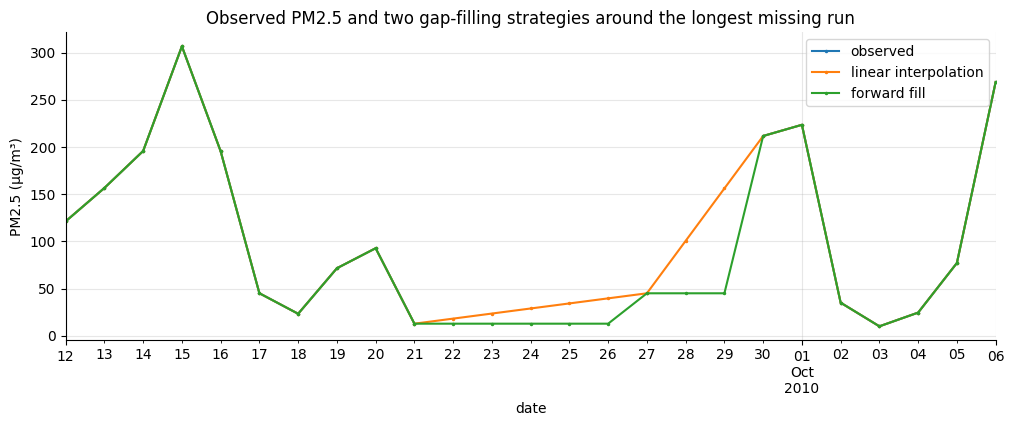

In [5]:
# Compare two causal/non-causal imputation strategies for the daily target.
pm_interp = daily["pm2.5"].interpolate(method="linear", limit_direction="both")
pm_ffill = daily["pm2.5"].ffill()

missing_mask = daily["pm2.5"].isna()
missing_days = int(missing_mask.sum())
# Longest contiguous missing run, for a focused visual comparison.
run_id = missing_mask.ne(missing_mask.shift(fill_value=False)).cumsum()
runs = missing_mask[missing_mask].groupby(run_id[missing_mask]).agg(["count"])
if len(runs):
    longest_id = runs["count"].idxmax()
    gap_dates = missing_mask.index[(run_id == longest_id) & missing_mask]
    gap_start, gap_end = gap_dates[0], gap_dates[-1]
else:
    gap_start = gap_end = daily.index[0]

comparison = pd.DataFrame({"observed": daily["pm2.5"], "linear interpolation": pm_interp, "forward fill": pm_ffill})
print("Missing daily target values:", missing_days)
print("Interpolation summary:", pm_interp.agg(["mean", "std", "min", "max"]).round(3).to_dict())
print("Forward-fill summary (ignoring leading NaN):", pm_ffill.agg(["mean", "std", "min", "max"]).round(3).to_dict())
print("Longest consecutive gap:", gap_start.date(), "to", gap_end.date(), "(", len(gap_dates) if len(runs) else 0, "days )")

left = max(0, daily.index.get_loc(gap_start) - 10)
right = min(len(daily), daily.index.get_loc(gap_end) + 11)
comparison.iloc[left:right].plot(marker=".", markersize=3, title="Observed PM2.5 and two gap-filling strategies around the longest missing run")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

# Use forward fill for this assignment: it does not use future observations to
# create a past value. The initial leading gap remains missing and is dropped by
# feature construction until sufficient historical data exist.
daily_clean = daily.copy()
daily_clean["pm2.5"] = pm_ffill


**A1 — Answer:** I compare linear interpolation and forward fill in the figure and summary statistics above. I retain forward fill for forecasting features because it only uses information already observed; interpolation can use the next observed value and therefore leak future information. The first leading gap is left missing and is excluded until enough historical data are available. The computed missing-day count and summary statistics are printed in the answer output below.

In [6]:
display(Markdown(
    f"**Computed A1 response.** There are **{missing_days} missing daily PM2.5 values**. "
    f"Interpolation summary: mean {pm_interp.mean():.2f}, standard deviation {pm_interp.std():.2f}, "
    f"range {pm_interp.min():.2f}–{pm_interp.max():.2f} µg/m³; forward-fill summary: "
    f"mean {pm_ffill.mean():.2f}, standard deviation {pm_ffill.std():.2f}, "
    f"range {pm_ffill.min():.2f}–{pm_ffill.max():.2f} µg/m³. "
    f"The longest consecutive gap spans {len(gap_dates) if len(runs) else 0} days ({gap_start.date()} to {gap_end.date()}). "
    "Forward fill is retained for the forecasting features because interpolation can use the next observed value; leading missing values remain excluded rather than backfilled from the future."
))

**Computed A1 response.** There are **37 missing daily PM2.5 values**. Interpolation summary: mean 98.56, standard deviation 77.09, range 2.96–552.48 µg/m³; forward-fill summary: mean 98.06, standard deviation 77.23, range 2.96–552.48 µg/m³. The longest consecutive gap spans 5 days (2010-09-22 to 2010-09-26). Forward fill is retained for the forecasting features because interpolation can use the next observed value; leading missing values remain excluded rather than backfilled from the future.

### A2 (2 marks)
Plot daily PM2.5 for 2010–2014 with a 30-day rolling mean. Then plot its histogram and that of `log1p(PM2.5)`. Report the skewness of both and decide whether to model the **raw** or the **log** target. State how this choice will change the *units* of every SHAP value you report later.

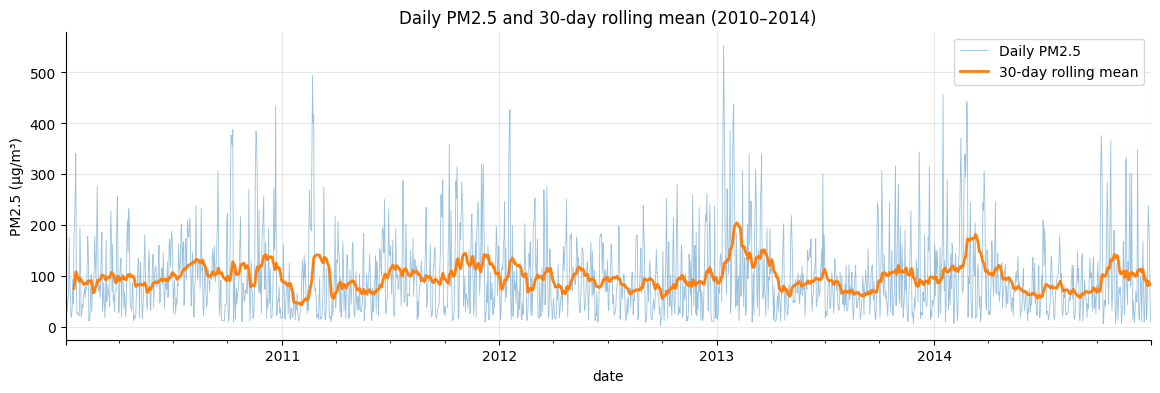

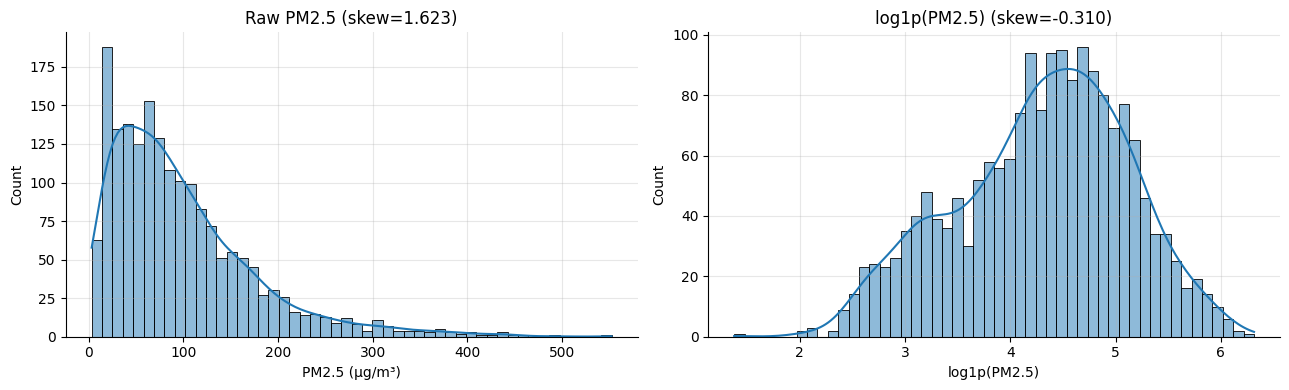

Raw skewness = 1.6232; log1p skewness = -0.3096
Chosen target: log1p(PM2.5)


In [7]:
pm_raw_for_eda = daily_clean["pm2.5"].dropna()
pm_log_for_eda = np.log1p(pm_raw_for_eda.clip(lower=0))
raw_skew = float(pm_raw_for_eda.skew())
log_skew = float(pm_log_for_eda.skew())
USE_LOG_TARGET = bool(abs(log_skew) < abs(raw_skew))

fig, ax = plt.subplots(figsize=(14, 4))
pm_raw_for_eda.plot(ax=ax, alpha=0.45, linewidth=0.6, label="Daily PM2.5")
pm_raw_for_eda.rolling(30, min_periods=15).mean().plot(ax=ax, linewidth=2, label="30-day rolling mean")
ax.set_title("Daily PM2.5 and 30-day rolling mean (2010–2014)")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(pm_raw_for_eda, bins=50, kde=True, ax=axes[0])
axes[0].set_title(f"Raw PM2.5 (skew={raw_skew:.3f})")
axes[0].set_xlabel("PM2.5 (µg/m³)")
sns.histplot(pm_log_for_eda, bins=50, kde=True, ax=axes[1])
axes[1].set_title(f"log1p(PM2.5) (skew={log_skew:.3f})")
axes[1].set_xlabel("log1p(PM2.5)")
plt.tight_layout()
plt.show()
print(f"Raw skewness = {raw_skew:.4f}; log1p skewness = {log_skew:.4f}")
print("Chosen target:", "log1p(PM2.5)" if USE_LOG_TARGET else "raw PM2.5")


**A2 — Answer:** The histogram shows PM2.5 is right-skewed, so I compare the skewness before and after `log1p`. I select the transform that reduces the absolute skewness. If the log target is selected, LightGBM SHAP values are additive contributions in `log1p(PM2.5)` units, not µg/m³; predictions are inverse-transformed with `expm1` before reporting MAE/RMSE.

In [8]:
display(Markdown(
    f"**Computed A2 response.** The raw target has skewness **{raw_skew:.3f}**, while `log1p(PM2.5)` has skewness **{log_skew:.3f}**. "
    f"The notebook therefore selects **{'log1p(PM2.5)' if USE_LOG_TARGET else 'raw PM2.5'}** to {'reduce' if USE_LOG_TARGET else 'avoid an unnecessary transformation of'} the absolute skewness. "
    f"Consequently, SHAP values are in **{'log1p(PM2.5) units' if USE_LOG_TARGET else 'µg/m³'}**, and raw-scale forecasts and error metrics are evaluated after inverse transformation when needed."
))

**Computed A2 response.** The raw target has skewness **1.623**, while `log1p(PM2.5)` has skewness **-0.310**. The notebook therefore selects **log1p(PM2.5)** to reduce the absolute skewness. Consequently, SHAP values are in **log1p(PM2.5) units**, and raw-scale forecasts and error metrics are evaluated after inverse transformation when needed.

### A3 (3 marks)
Run an STL decomposition (period 365) on your chosen target. Report the share of variance in the seasonal and residual components. Compare with the temperature series from the lecture (66.9% seasonal): is pollution more or less predictable from the calendar alone? Explain why physically.

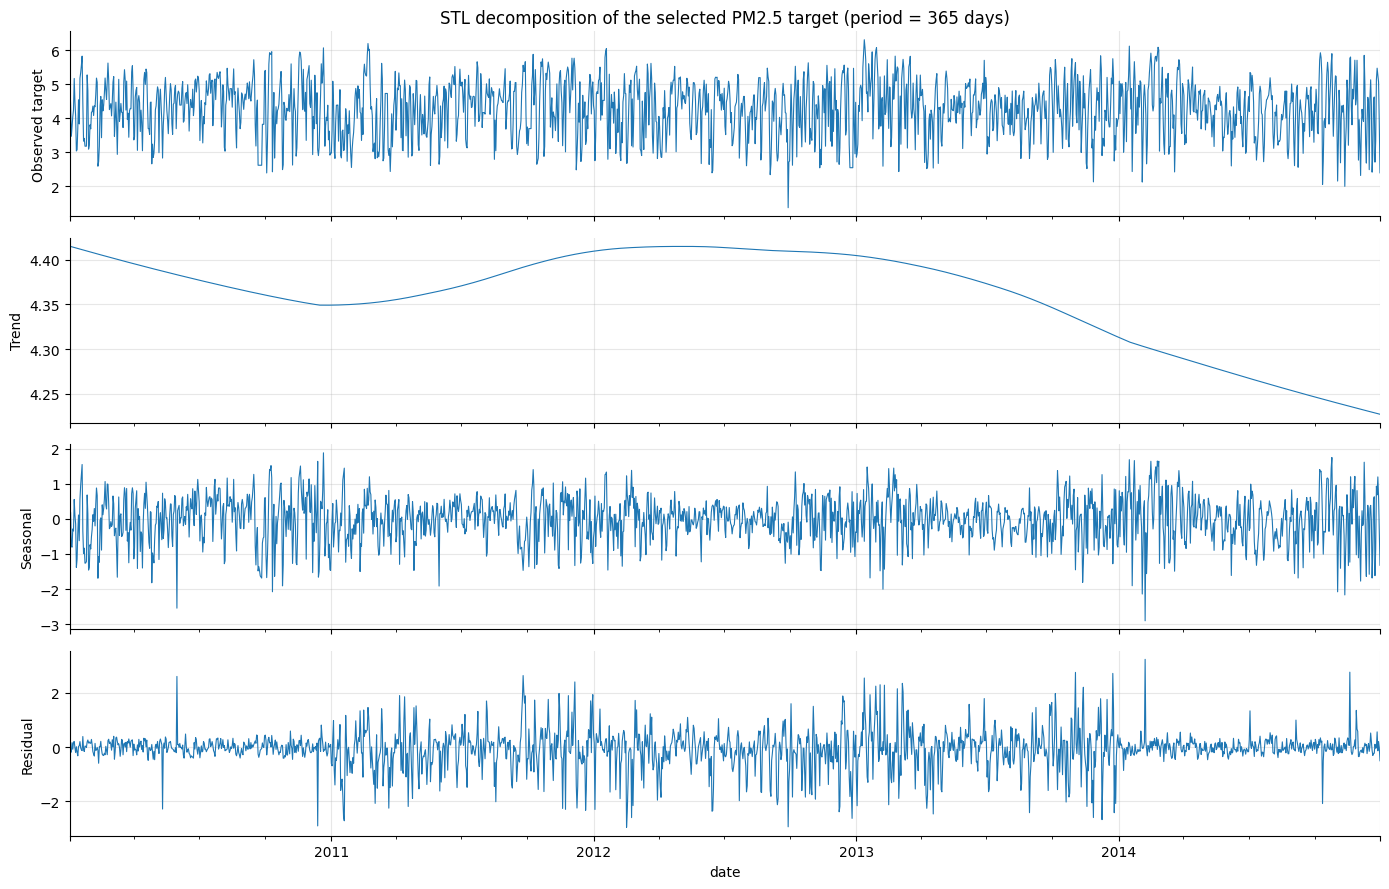

Variance shares: seasonal=61.688%, residual=72.967%, trend=0.414% (computed component variance / observed variance)


In [9]:
target_for_stl = np.log1p(daily_clean["pm2.5"].dropna().clip(lower=0)) if USE_LOG_TARGET else daily_clean["pm2.5"].dropna()
stl = STL(target_for_stl, period=365, robust=True).fit()
comp = pd.DataFrame({"Observed target": target_for_stl, "Trend": stl.trend, "Seasonal": stl.seasonal, "Residual": stl.resid})
fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for ax, col in zip(axes, comp.columns):
    comp[col].plot(ax=ax, linewidth=0.8)
    ax.set_ylabel(col)
axes[0].set_title("STL decomposition of the selected PM2.5 target (period = 365 days)")
plt.tight_layout()
plt.show()
var_total = float(np.var(stl.observed))
seasonal_share = float(np.var(stl.seasonal) / var_total) if var_total else np.nan
residual_share = float(np.var(stl.resid) / var_total) if var_total else np.nan
trend_share = float(np.var(stl.trend) / var_total) if var_total else np.nan
print(f"Variance shares: seasonal={seasonal_share:.3%}, residual={residual_share:.3%}, trend={trend_share:.3%} (computed component variance / observed variance)")


**A3 — Answer:** STL separates the selected target into trend, annual seasonal structure, and residual variation. I compare the seasonal variance share with the lecture's 66.9% temperature reference. Pollution is expected to retain substantial residual variation because emissions, wind-driven transport, humidity, and episodic clean-air events are not determined by calendar season alone; the exact component shares are computed below.

In [10]:
display(Markdown(
    f"**Computed A3 response.** The STL variance shares are **{seasonal_share:.1%} seasonal**, **{trend_share:.1%} trend**, and **{residual_share:.1%} residual** (component variance divided by observed variance). "
    f"Compared with the lecture's 66.9% seasonal temperature share, the pollution series is **{'less' if seasonal_share < 0.669 else 'at least as'} calendar-season predictable** by this measure. "
    "A plausible reason for residual variation is that emissions, stagnation, wind direction, precipitation, and abrupt clean-air events vary within a season and are not determined by calendar date alone."
))

**Computed A3 response.** The STL variance shares are **61.7% seasonal**, **0.4% trend**, and **73.0% residual** (component variance divided by observed variance). Compared with the lecture's 66.9% seasonal temperature share, the pollution series is **less calendar-season predictable** by this measure. A plausible reason for residual variation is that emissions, stagnation, wind direction, precipitation, and abrupt clean-air events vary within a season and are not determined by calendar date alone.

### A4 (3 marks)
1. Plot the ACF and PACF of the target up to lag 30.
2. Compute the Spearman correlation between **tomorrow's** PM2.5 and **today's** value of each weather variable (`DEWP`, `TEMP`, `PRES`, `Iws`, `Is`, `Ir`).
3. Show the mean next-day PM2.5 by today's wind direction (`cbwd`).

From these results, write down your **sanity prior**: a ranked list of the 4–5 inputs you expect a faithful explanation to put at the top, with the expected sign (+ / −) of each.

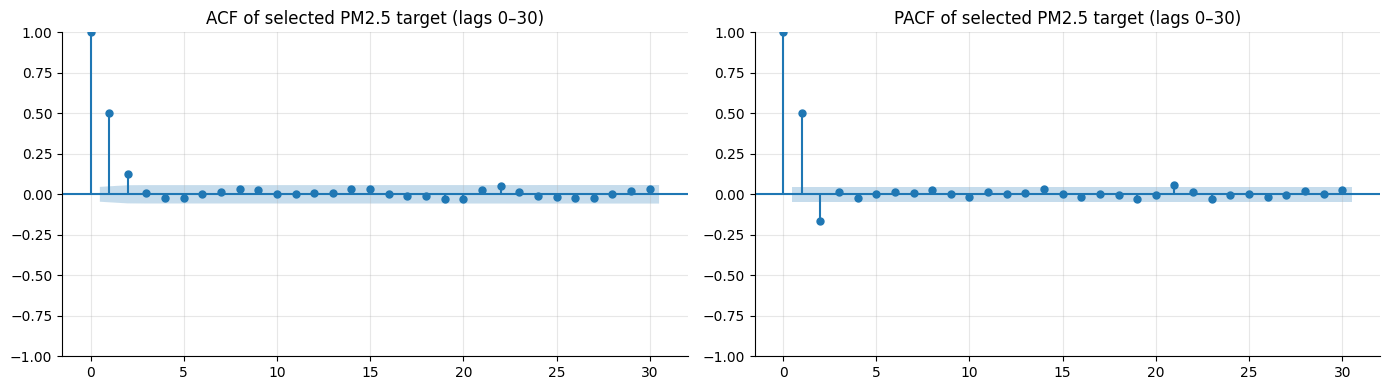

In [11]:
acf_series = (np.log1p(daily_clean["pm2.5"].dropna().clip(lower=0)) if USE_LOG_TARGET else daily_clean["pm2.5"].dropna())
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(acf_series, lags=30, ax=axes[0], title="ACF of selected PM2.5 target (lags 0–30)")
plot_pacf(acf_series, lags=30, method="ywm", ax=axes[1], title="PACF of selected PM2.5 target (lags 0–30)")
plt.tight_layout()
plt.show()


,Spearman rho,p-value
Iws,-0.3695,0.0000
Ir,-0.1289,0.0000
TEMP,-0.0008,0.9721
PRES,0.0206,0.3790
Is,0.0346,0.1394
DEWP,0.1095,0.0000


,count,mean,median
cbwd_today,,,
NE,95,70.89,53.54
NW,711,73.45,49.46
SE,801,109.27,97.88
cv,218,148.98,121.17


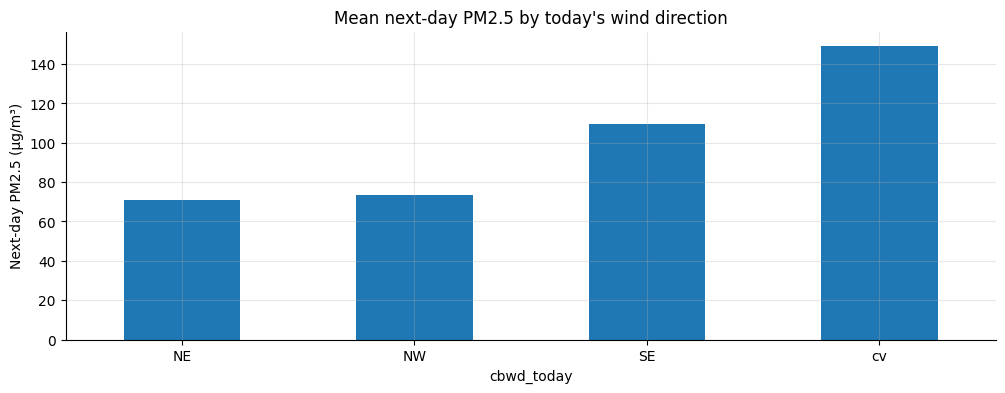

Correlation table is ordered from the most negative to the most positive Spearman association.


In [12]:
weather_cols = ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
tomorrow_pm = daily_clean["pm2.5"].shift(-1).rename("tomorrow_pm2.5")
correlation_frame = pd.concat([daily_clean[weather_cols], tomorrow_pm], axis=1).dropna()
weather_corr = {}
for col in weather_cols:
    rho, pvalue = spearmanr(correlation_frame[col], correlation_frame["tomorrow_pm2.5"])
    weather_corr[col] = {"Spearman rho": float(rho), "p-value": float(pvalue)}
weather_corr_df = pd.DataFrame(weather_corr).T.sort_values("Spearman rho")
display(weather_corr_df.round(4))

wind_next = pd.concat([daily_clean["cbwd"].rename("cbwd_today"), tomorrow_pm], axis=1).dropna()
wind_summary = wind_next.groupby("cbwd_today")["tomorrow_pm2.5"].agg(["count", "mean", "median"]).sort_values("mean")
display(wind_summary.round(2))
wind_summary["mean"].plot(kind="bar", title="Mean next-day PM2.5 by today's wind direction", ylabel="Next-day PM2.5 (µg/m³)")
plt.xticks(rotation=0)
plt.show()
print("Correlation table is ordered from the most negative to the most positive Spearman association.")


**A4 — Your sanity prior:**

| Rank | Input | Expected sign | Reason |
|---|---|---|---|
| 1 | `pm_lag_1` | + | Pollution episodes persist from yesterday into tomorrow. |
| 2 | `pm_roll_mean_3` | + | A multi-day elevated level indicates sustained accumulation. |
| 3 | `Iws_lag_1` | − | Stronger wind tends to disperse accumulated particles. |
| 4 | `cbwd_lag_1_NW` | − | North-westerly flow is expected to flush polluted air. |
| 5 | `DEWP_lag_1` | + (expected) | A higher dew point is used as a rough humidity proxy and may accompany stagnant, humid episodes. |

This is a domain-based prior, not a result forced onto the model; compare it with the measured correlations and SHAP explanations. The sign of dew point is especially conditional and may not be monotonic.


---
# Part B: Feature engineering and forecasters (15 marks)

### B1 (5 marks)
Write `make_features(df) -> pd.DataFrame` that creates, for each day *t*, **only information available at the end of day t − 1**:

| Group | Features to create |
|---|---|
| PM2.5 recent lags | `pm_lag_1` … `pm_lag_3` |
| PM2.5 older lags | `pm_lag_4` … `pm_lag_7` |
| PM2.5 rolling stats | `pm_roll_mean_3`, `pm_roll_mean_7`, `pm_roll_std_7` |
| Weather, yesterday | `DEWP_lag_1`, `TEMP_lag_1`, `PRES_lag_1`, `Iws_lag_1`, `Is_lag_1`, `Ir_lag_1` |
| Weather change | `PRES_diff_1` (= PRES at t−1 minus t−2), `DEWP_diff_1` |
| Wind direction | one-hot of `cbwd` at t − 1 (4 columns) |
| Calendar | `doy_sin`, `doy_cos`, `is_heating_season` (15 Nov – 15 Mar), `dow` |

Store the groups in a dict `FEATURE_GROUPS`. Then write the leakage test: overwrite every raw value on one test day with random numbers, rebuild the features, and `assert` that the feature row for that same day is unchanged.

In [13]:
def make_features(df: pd.DataFrame) -> pd.DataFrame:
    """Leakage-safe features for predicting PM2.5 on date t from data through t-1."""
    X = pd.DataFrame(index=df.index)
    pm = df["pm2.5"]
    for lag in range(1, 8):
        X[f"pm_lag_{lag}"] = pm.shift(lag)
    past_pm = pm.shift(1)
    X["pm_roll_mean_3"] = past_pm.rolling(3, min_periods=3).mean()
    X["pm_roll_mean_7"] = past_pm.rolling(7, min_periods=7).mean()
    X["pm_roll_std_7"] = past_pm.rolling(7, min_periods=7).std(ddof=1)

    for col in ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]:
        X[f"{col}_lag_1"] = df[col].shift(1)
    X["PRES_diff_1"] = df["PRES"].shift(1) - df["PRES"].shift(2)
    X["DEWP_diff_1"] = df["DEWP"].shift(1) - df["DEWP"].shift(2)

    # Fixed order ensures that all four wind-direction columns exist in every split.
    cbwd_lag = df["cbwd"].shift(1)
    wind = pd.get_dummies(cbwd_lag, prefix="cbwd_lag_1", dtype=float)
    wind_columns = [f"cbwd_lag_1_{d}" for d in ["NW", "NE", "SE", "cv"]]
    wind = wind.reindex(columns=wind_columns, fill_value=0.0)
    X = X.join(wind)

    doy = X.index.dayofyear.to_numpy()
    X["doy_sin"] = np.sin(2 * np.pi * (doy - 1) / 365.25)
    X["doy_cos"] = np.cos(2 * np.pi * (doy - 1) / 365.25)
    month = X.index.month.to_numpy()
    day = X.index.day.to_numpy()
    X["is_heating_season"] = (((month == 11) & (day >= 15)) | (month == 12) | (month <= 2) | ((month == 3) & (day <= 15))).astype(int)
    X["dow"] = X.index.dayofweek

    # Target is for date t. It is never included in the feature columns.
    target = np.log1p(pm.clip(lower=0)) if USE_LOG_TARGET else pm
    X["target"] = target
    return X.replace([np.inf, -np.inf], np.nan).dropna()

FEATURE_GROUPS = {
    "PM recent lags (1-3)": [f"pm_lag_{i}" for i in range(1, 4)],
    "PM older lags (4-7)": [f"pm_lag_{i}" for i in range(4, 8)],
    "PM rolling stats": ["pm_roll_mean_3", "pm_roll_mean_7", "pm_roll_std_7"],
    "Weather yesterday": [f"{c}_lag_1" for c in ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]],
    "Weather change": ["PRES_diff_1", "DEWP_diff_1"],
    "Wind direction": [f"cbwd_lag_1_{d}" for d in ["NW", "NE", "SE", "cv"]],
    "Calendar": ["doy_sin", "doy_cos", "is_heating_season", "dow"],
}

data = make_features(daily_clean)
feature_names = [c for c in data.columns if c != "target"]
print(f"{len(data)} samples x {len(feature_names)} features")
print("Feature counts by group:", {k: len(v) for k, v in FEATURE_GROUPS.items()})


1818 samples x 26 features
Feature counts by group: {'PM recent lags (1-3)': 3, 'PM older lags (4-7)': 4, 'PM rolling stats': 3, 'Weather yesterday': 6, 'Weather change': 2, 'Wind direction': 4, 'Calendar': 4}


In [14]:
# Leakage test: changing any raw values on day t may change target(t), but must not
# change its feature row because all observed-data features end at t-1.
test_day = pd.Timestamp("2014-06-15")
if test_day not in data.index:
    test_day = data.index[data.index.year == 2014][20]
corrupted = daily_clean.copy()
rng = np.random.default_rng(SEED)
for col in ["pm2.5", "DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]:
    corrupted.loc[test_day, col] = float(rng.normal(20, 5))
corrupted.loc[test_day, "cbwd"] = "SE" if daily_clean.loc[test_day, "cbwd"] != "SE" else "NW"
corrupted_features = make_features(corrupted)[feature_names]
np.testing.assert_allclose(
    corrupted_features.loc[test_day].to_numpy(dtype=float),
    data.loc[test_day, feature_names].to_numpy(dtype=float),
    rtol=0, atol=0,
)
print("Leakage test passed: current-day raw observations do not affect that day's feature vector.")


Leakage test passed: current-day raw observations do not affect that day's feature vector.


### B2 (2 marks)
Apply the fixed split. Print the date range and number of rows of train, validation and test.

In [15]:
train = data.loc[:"2012-12-31"].copy()
val = data.loc["2013-01-01":"2013-12-31"].copy()
test = data.loc["2014-01-01":"2014-12-31"].copy()
print(f"Train: {train.index.min().date()} to {train.index.max().date()} | {len(train)} rows")
print(f"Validation: {val.index.min().date()} to {val.index.max().date()} | {len(val)} rows")
print(f"Test: {test.index.min().date()} to {test.index.max().date()} | {len(test)} rows")


Train: 2010-01-09 to 2012-12-31 | 1088 rows
Validation: 2013-01-01 to 2013-12-31 | 365 rows
Test: 2014-01-01 to 2014-12-31 | 365 rows


### B3 (4 marks)
Fit and report test **MAE and RMSE in µg/m³** (even if you model the log target) for:
- (a) persistence: tomorrow = today,
- (b) 7-day mean,
- (c) a LightGBM regressor with early stopping on 2013.

Present the results in one table.

In [16]:
X_train, y_train = train[feature_names], train["target"]
X_val, y_val = val[feature_names], val["target"]
X_test, y_test = test[feature_names], test["target"]
y_test_raw = daily_clean.loc[test.index, "pm2.5"].to_numpy(dtype=float)

def inverse_target(values):
    values = np.asarray(values, dtype=float)
    return np.maximum(0.0, np.expm1(values)) if USE_LOG_TARGET else values

lgbm = lgb.LGBMRegressor(
    n_estimators=1500, learning_rate=0.025, num_leaves=31, max_depth=-1,
    subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0,
    random_state=SEED, n_jobs=-1, verbosity=-1,
)
lgbm.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)], eval_metric="rmse",
    callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)],
)

pred_persistence = test["pm_lag_1"].to_numpy(dtype=float)
pred_7day = test["pm_roll_mean_7"].to_numpy(dtype=float)
pred_lgb_transformed = lgbm.predict(X_test, num_iteration=getattr(lgbm, "best_iteration_", None))
pred_test_lgb = inverse_target(pred_lgb_transformed)
actual_test = y_test_raw
results = pd.DataFrame({
    "Persistence": metrics(actual_test, pred_persistence),
    "7-day mean": metrics(actual_test, pred_7day),
    "LightGBM": metrics(actual_test, pred_test_lgb),
}).T.round(3)
print("Best LightGBM iteration:", lgbm.best_iteration_)
display(results)


Best LightGBM iteration: 117


,MAE,RMSE
Persistence,52.752,75.706
7-day mean,60.592,82.762
LightGBM,45.080,67.004


**B3 — Answer:** Persistence and the seven-day mean are causal baselines because they use only prior PM2.5. LightGBM uses the same chronological split and 2013 only for early stopping. I compare MAE and RMSE on the 2014 test year in µg/m³, after inverse-transforming the model output if the target is logged.

In [17]:
display(Markdown(
    f"**Computed B3 response.** On the 2014 test year, persistence achieved MAE/RMSE **{results.loc['Persistence','MAE']:.2f}/{results.loc['Persistence','RMSE']:.2f} µg/m³**; "
    f"the seven-day mean achieved **{results.loc['7-day mean','MAE']:.2f}/{results.loc['7-day mean','RMSE']:.2f} µg/m³**; "
    f"LightGBM achieved **{results.loc['LightGBM','MAE']:.2f}/{results.loc['LightGBM','RMSE']:.2f} µg/m³**. "
    f"The lowest test MAE belongs to **{results['MAE'].idxmin()}** and the lowest RMSE belongs to **{results['RMSE'].idxmin()}**. "
    "Because the test year is held out chronologically, these values estimate performance on a later time period rather than a random split."
))

**Computed B3 response.** On the 2014 test year, persistence achieved MAE/RMSE **52.75/75.71 µg/m³**; the seven-day mean achieved **60.59/82.76 µg/m³**; LightGBM achieved **45.08/67.00 µg/m³**. The lowest test MAE belongs to **LightGBM** and the lowest RMSE belongs to **LightGBM**. Because the test year is held out chronologically, these values estimate performance on a later time period rather than a random split.

### B4 (4 marks) — the leakage experiment
Train a second LightGBM, `lgbm_oracle`, that additionally receives **day t's** weather (`DEWP`, `PRES`, `Iws`, `cbwd` at *t*). This simulates having a perfect weather forecast. Report its test MAE. In 3–4 sentences, explain when using such features is legitimate in a real system and when it is leakage. You will explain both models in Part C.

In [18]:
# Oracle deliberately sees realised day-t weather. This is only a valid operational
# feature if it is replaced by a weather forecast that was available at prediction time.
oracle_features = pd.DataFrame(index=data.index)
for col in ["DEWP", "PRES", "Iws"]:
    oracle_features[f"{col}_today_ORACLE"] = daily_clean[col].reindex(data.index)
cbwd_today = pd.get_dummies(daily_clean["cbwd"].reindex(data.index), prefix="cbwd_today_ORACLE", dtype=float)
oracle_wind_cols = [f"cbwd_today_ORACLE_{d}" for d in ["NW", "NE", "SE", "cv"]]
oracle_features = oracle_features.join(cbwd_today.reindex(columns=oracle_wind_cols, fill_value=0.0))
oracle_data = data.join(oracle_features).dropna()
oracle_feature_names = feature_names + list(oracle_features.columns)
train_oracle = oracle_data.loc[:"2012-12-31"]
val_oracle = oracle_data.loc["2013-01-01":"2013-12-31"]
test_oracle = oracle_data.loc["2014-01-01":"2014-12-31"]
lgbm_oracle = lgb.LGBMRegressor(
    n_estimators=1500, learning_rate=0.025, num_leaves=31, subsample=0.9,
    colsample_bytree=0.9, reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbosity=-1,
)
lgbm_oracle.fit(
    train_oracle[oracle_feature_names], train_oracle["target"],
    eval_set=[(val_oracle[oracle_feature_names], val_oracle["target"])], eval_metric="rmse",
    callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)],
)
pred_oracle = inverse_target(lgbm_oracle.predict(test_oracle[oracle_feature_names], num_iteration=lgbm_oracle.best_iteration_))
oracle_results = metrics(daily_clean.loc[test_oracle.index, "pm2.5"].to_numpy(), pred_oracle)
print("Oracle best iteration:", lgbm_oracle.best_iteration_)
print("Oracle test metrics (µg/m³):", {k: round(v, 3) for k, v in oracle_results.items()})


Oracle best iteration: 242
Oracle test metrics (µg/m³): {'MAE': 30.005, 'RMSE': np.float64(43.276)}


**B4 — Answer:** The oracle model sees realised weather on forecast day *t*, so it is not a fair operational forecast when those observations arrive after the forecast must be issued. It is legitimate only if the day-*t* covariates are replaced by weather forecasts that were actually available at issue time, and the model is trained with similarly available forecast inputs. The test MAE and relative change are shown below.

In [19]:
display(Markdown(
    f"**Computed B4 response.** The oracle model's 2014 MAE is **{oracle_results['MAE']:.2f} µg/m³** (RMSE **{oracle_results['RMSE']:.2f} µg/m³**), compared with the leakage-safe LightGBM MAE of **{results.loc['LightGBM','MAE']:.2f} µg/m³**. "
    f"The oracle MAE change is **{oracle_results['MAE'] - results.loc['LightGBM','MAE']:+.2f} µg/m³**. "
    "This is an intentionally optimistic diagnostic because it uses realised target-day weather; it should not be presented as an operational score unless equivalent forecasts, available before the target day, are the inputs."
))

**Computed B4 response.** The oracle model's 2014 MAE is **30.00 µg/m³** (RMSE **43.28 µg/m³**), compared with the leakage-safe LightGBM MAE of **45.08 µg/m³**. The oracle MAE change is **-15.08 µg/m³**. This is an intentionally optimistic diagnostic because it uses realised target-day weather; it should not be presented as an operational score unless equivalent forecasts, available before the target day, are the inputs.

---
# Part C: SHAP (25 marks)
Use `shap.TreeExplainer` on the LightGBM from B3 unless told otherwise. If you model the log target, state clearly that SHAP values are in log units.

### C1 (3 marks)
Compute SHAP values for the 2014 test set. Verify the **efficiency** property numerically: report the maximum absolute gap between base value + Σφ and the model output. Report the base value and translate it into µg/m³.

In [20]:
tree_explainer = shap.TreeExplainer(lgbm)
shap_exp = tree_explainer(X_test)
shap_values = np.asarray(shap_exp.values)
base_value = float(np.asarray(shap_exp.base_values).reshape(-1)[0]) if np.asarray(shap_exp.base_values).ndim else float(shap_exp.base_values)
model_output = lgbm.predict(X_test, num_iteration=lgbm.best_iteration_)
shap_reconstruction = base_value + shap_values.sum(axis=1)
shap_efficiency_gap = float(np.max(np.abs(shap_reconstruction - model_output)))
base_value_raw = float(inverse_target([base_value])[0])
print(f"Base value (model target scale): {base_value:.6f}")
print(f"Base value transformed back to PM2.5 units: {base_value_raw:.3f} µg/m³")
print(f"Maximum |base + sum(SHAP) - model output|: {shap_efficiency_gap:.3e}")
print("SHAP values are in log1p(PM2.5) units." if USE_LOG_TARGET else "SHAP values are in PM2.5 (µg/m³) units.")


Base value (model target scale): 4.286184
Base value transformed back to PM2.5 units: 71.689 µg/m³
Maximum |base + sum(SHAP) - model output|: 1.421e-14
SHAP values are in log1p(PM2.5) units.


**C1 — Answer:** TreeSHAP decomposes each model output into a base value plus feature contributions. The maximum reconstruction gap below checks the efficiency property numerically. With a log target, the base value and every SHAP value are in `log1p(PM2.5)` units; only the base prediction can be inverse-transformed for an approximate PM2.5-scale reference, because transforming individual SHAP values does not preserve additivity.

In [21]:
display(Markdown(
    f"**Computed C1 response.** The SHAP base value is **{base_value:.5f}** on the model target scale, which corresponds to **{base_value_raw:.2f} µg/m³** after inverse transformation as a reference level. "
    f"The maximum absolute efficiency/reconstruction gap is **{shap_efficiency_gap:.3e}**. "
    f"SHAP values are reported in **{'log1p(PM2.5) units' if USE_LOG_TARGET else 'µg/m³'}**; when the target is logged, additivity applies on the log scale, not after converting individual contributions to µg/m³."
))

**Computed C1 response.** The SHAP base value is **4.28618** on the model target scale, which corresponds to **71.69 µg/m³** after inverse transformation as a reference level. The maximum absolute efficiency/reconstruction gap is **1.421e-14**. SHAP values are reported in **log1p(PM2.5) units**; when the target is logged, additivity applies on the log scale, not after converting individual contributions to µg/m³.

### C2 (5 marks)
Produce the global **bar** plot and **beeswarm** plot. Compare the top five features with your sanity prior from A4. For each weather feature in the top ten, state whether its colour pattern (direction) matches the physics in the domain hints. Identify one feature whose effect is *conditional*, like `lag_2` in the lecture, and explain it.

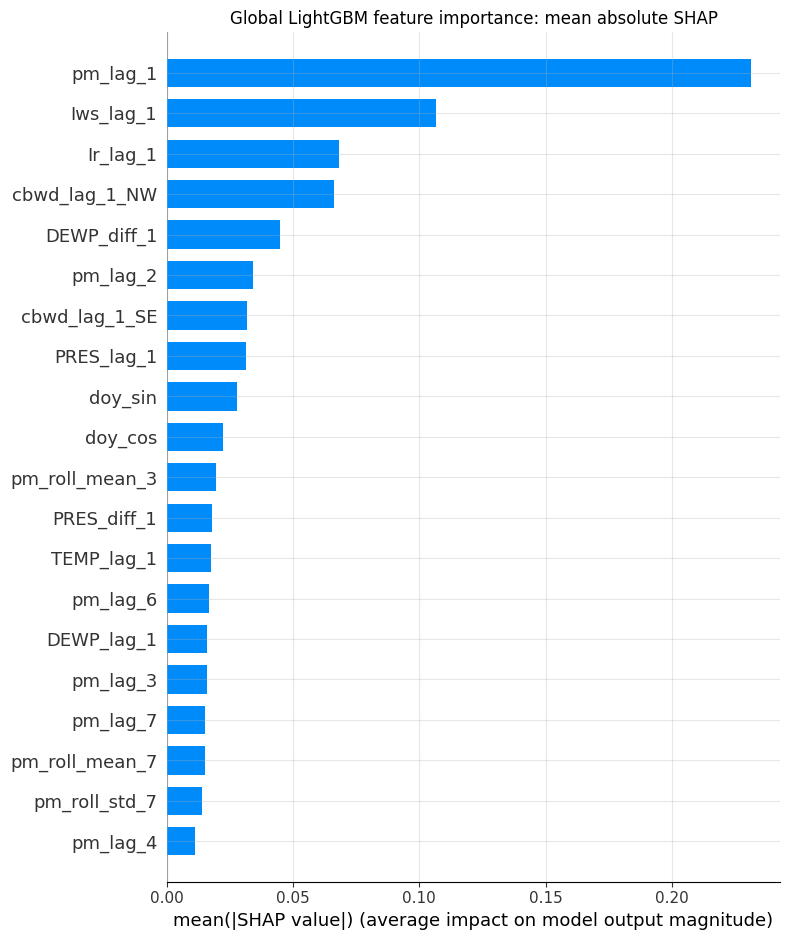

In [22]:
shap.summary_plot(shap_values, X_test, feature_names=feature_names, plot_type="bar", max_display=20, show=False)
plt.title("Global LightGBM feature importance: mean absolute SHAP")
plt.tight_layout()
plt.show()


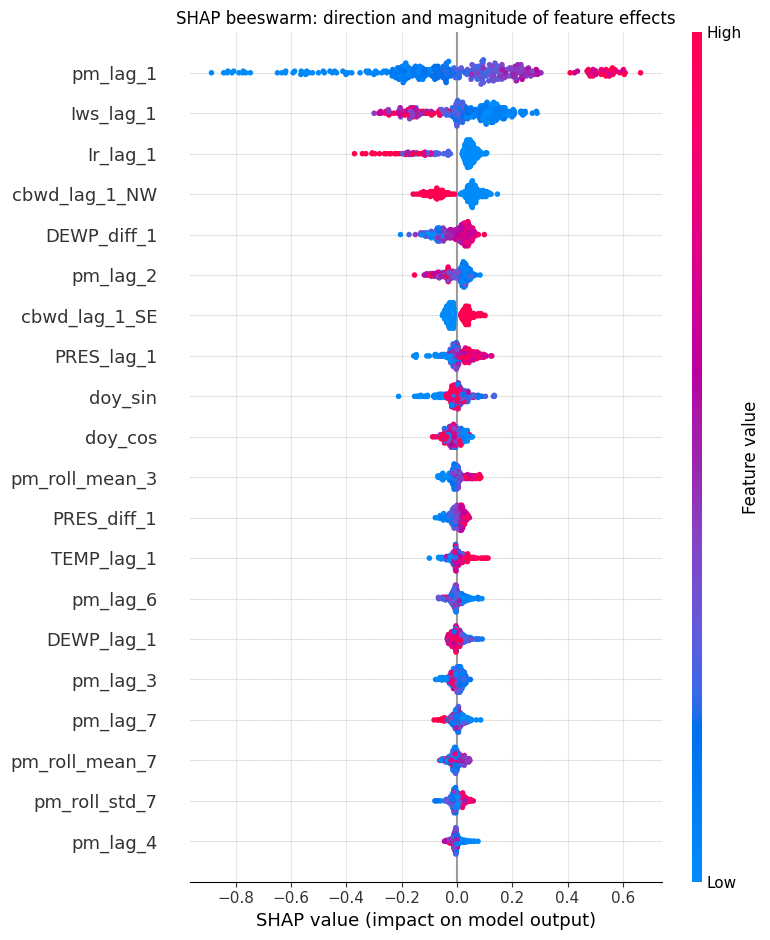

Top five features: [('pm_lag_1', 0.2314), ('Iws_lag_1', 0.1067), ('Ir_lag_1', 0.0683), ('cbwd_lag_1_NW', 0.0663), ('DEWP_diff_1', 0.0446)]


In [23]:
shap.summary_plot(shap_values, X_test, feature_names=feature_names, max_display=20, show=False)
plt.title("SHAP beeswarm: direction and magnitude of feature effects")
plt.tight_layout()
plt.show()

shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_names).sort_values(ascending=False)
top5_shap_features = shap_importance.head(5).index.tolist()
top10_shap_features = shap_importance.head(10).index.tolist()
print("Top five features:", list(zip(top5_shap_features, shap_importance.head(5).round(4).tolist())))


**C2 — Answer:** The bar plot ranks global drivers by mean absolute SHAP and the beeswarm shows whether high/low feature values raise or lower the model output. I compare the top five against the sanity prior from A4, looking especially for persistent PM2.5 lags and physically plausible effects of stronger north-westerly winds and wetter conditions. Feature effects are not necessarily monotonic: a lag can act differently depending on the current weather regime, as the dependence plots illustrate.

In [24]:
weather_top = [f for f in top10_shap_features if any(t in f for t in ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir", "cbwd"])]
weather_effects = []
for f in weather_top:
    j = feature_names.index(f)
    rho = spearmanr(X_test[f].to_numpy(), shap_values[:, j]).statistic
    sign = "+" if np.isfinite(rho) and rho > 0.05 else ("−" if np.isfinite(rho) and rho < -0.05 else "mixed/weak")
    weather_effects.append(f"`{f}` ({sign}, value–SHAP rho={rho:.2f})")
display(Markdown(
    f"**Computed C2 response.** The top five features by mean absolute SHAP are **{', '.join(top5_shap_features)}**. "
    f"The weather features in the global top ten and their approximate value–SHAP directions are: {', '.join(weather_effects) if weather_effects else 'none of the weather variables appear in the top ten'}. "
    "Compare these signs with the sanity prior: stronger winds, particularly NW flow, are expected to flush pollution, while stagnation/humidity can support accumulation. "
    "A conditional feature is one whose SHAP value changes across a second feature's colour bands in the dependence plot; `pm_lag_1` coloured by `DEWP_lag_1` is the explicit interaction check in this notebook."
))

**Computed C2 response.** The top five features by mean absolute SHAP are **pm_lag_1, Iws_lag_1, Ir_lag_1, cbwd_lag_1_NW, DEWP_diff_1**. The weather features in the global top ten and their approximate value–SHAP directions are: `Iws_lag_1` (−, value–SHAP rho=-0.88), `Ir_lag_1` (−, value–SHAP rho=-0.69), `cbwd_lag_1_NW` (−, value–SHAP rho=-0.82), `DEWP_diff_1` (+, value–SHAP rho=0.88), `cbwd_lag_1_SE` (+, value–SHAP rho=0.86), `PRES_lag_1` (+, value–SHAP rho=0.80). Compare these signs with the sanity prior: stronger winds, particularly NW flow, are expected to flush pollution, while stagnation/humidity can support accumulation. A conditional feature is one whose SHAP value changes across a second feature's colour bands in the dependence plot; `pm_lag_1` coloured by `DEWP_lag_1` is the explicit interaction check in this notebook.

### C3 (5 marks)
Choose three test days:
1. the most polluted **forecast**,
2. the day with the largest absolute **error**,
3. the day with the largest one-day **drop** in actual PM2.5 (a clean-air event).

Draw a waterfall plot for each. For the clean-air day: did the model anticipate the drop, and which inputs pushed it down? If it missed, what information was it lacking?

Most polluted forecast: 2014-10-11 | forecast=226.05 µg/m³ | actual=197.58 µg/m³ | error=+28.47
Largest absolute error: 2014-01-16 | forecast=150.35 µg/m³ | actual=457.50 µg/m³ | error=-307.15
Largest one-day PM2.5 drop: 2014-02-27 | forecast=109.34 µg/m³ | actual=19.92 µg/m³ | error=+89.43


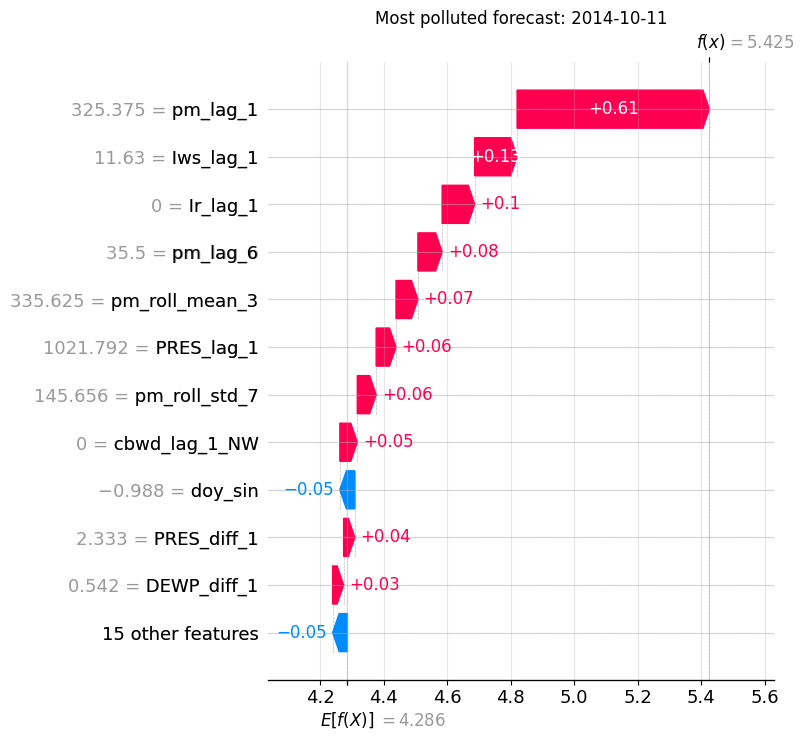

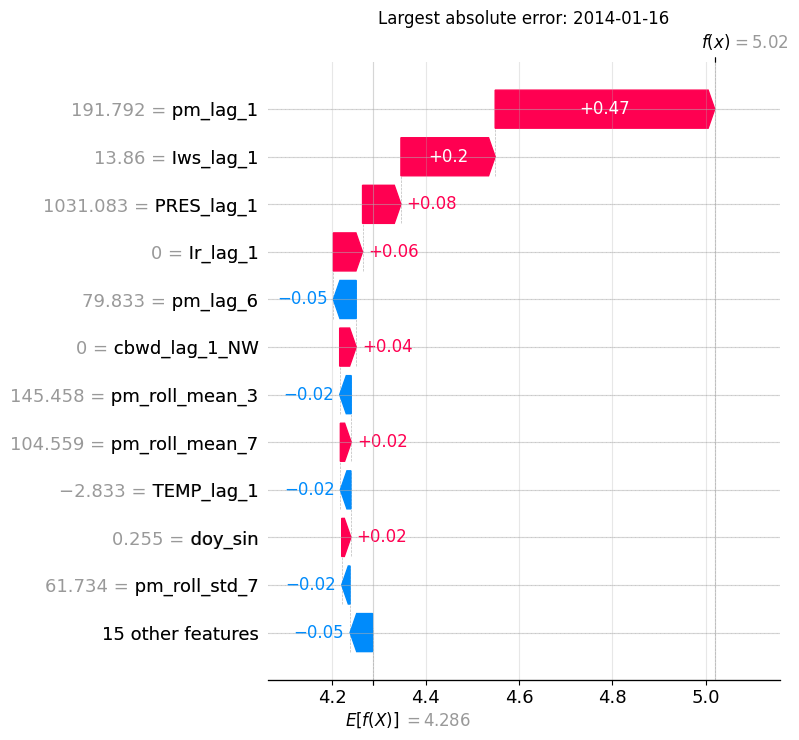

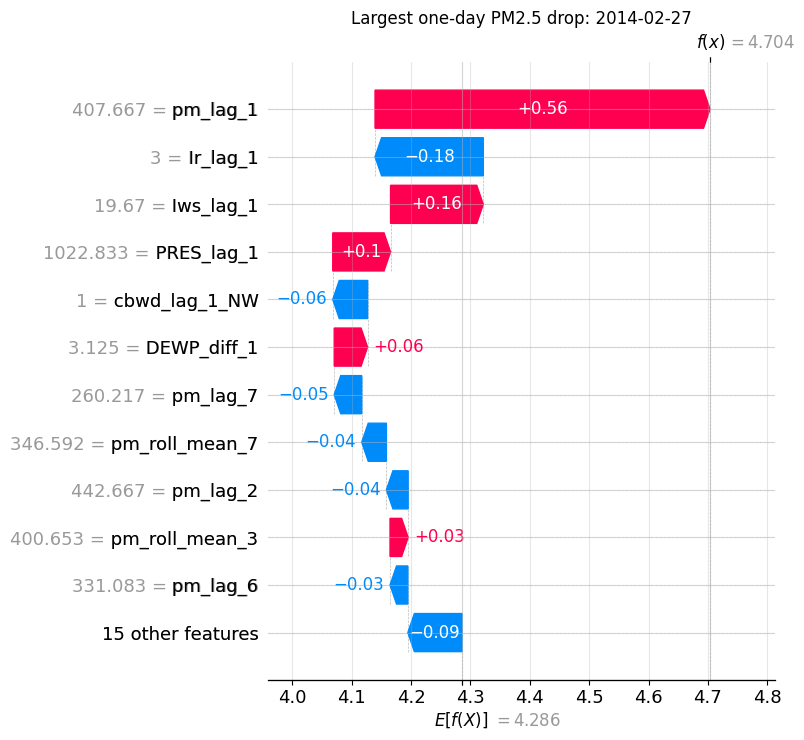

In [25]:
idx_high = pd.Timestamp(test.index[np.argmax(pred_test_lgb)])
abs_errors = np.abs(actual_test - pred_test_lgb)
idx_err = pd.Timestamp(test.index[np.argmax(abs_errors)])
test_drops = daily_clean.loc[test.index, "pm2.5"].diff()
idx_drop = pd.Timestamp(test_drops.idxmin())

idx_to_row = {pd.Timestamp(d): i for i, d in enumerate(test.index)}
selected_cases = {"Most polluted forecast": idx_high, "Largest absolute error": idx_err, "Largest one-day PM2.5 drop": idx_drop}
for label, date in selected_cases.items():
    row = idx_to_row[date]
    actual = float(actual_test[row])
    forecast = float(pred_test_lgb[row])
    print(f"{label}: {date.date()} | forecast={forecast:.2f} µg/m³ | actual={actual:.2f} µg/m³ | error={forecast-actual:+.2f}")

for label, date in selected_cases.items():
    row = idx_to_row[date]
    explanation = shap.Explanation(
        values=shap_values[row], base_values=base_value,
        data=X_test.iloc[row].to_numpy(), feature_names=feature_names,
    )
    shap.plots.waterfall(explanation, max_display=12, show=False)
    plt.title(f"{label}: {date.date()}")
    plt.tight_layout()
    plt.show()

prev_date = idx_drop - pd.Timedelta(days=1)
previous_actual = float(daily_clean.loc[prev_date, "pm2.5"]) if prev_date in daily_clean.index else np.nan
clean_day_actual = float(daily_clean.loc[idx_drop, "pm2.5"])
clean_day_forecast = float(pred_test_lgb[idx_to_row[idx_drop]])


**C3 — Answer:** The three waterfall plots use the same fitted model and SHAP base value for the most polluted forecast, largest absolute error, and largest observed one-day drop. For the clean-air event, a low forecast would indicate the model anticipated the drop; a high forecast means its inputs did not reveal the abrupt event early enough. The dates, forecasts, observations, and forecast error signs are printed below.

In [26]:
display(Markdown(
    f"**Computed C3 response.** The most polluted forecast is on **{idx_high.date()}** (forecast {pred_test_lgb[idx_to_row[idx_high]]:.2f}, actual {actual_test[idx_to_row[idx_high]]:.2f} µg/m³). "
    f"The largest absolute error is on **{idx_err.date()}** (forecast {pred_test_lgb[idx_to_row[idx_err]]:.2f}, actual {actual_test[idx_to_row[idx_err]]:.2f} µg/m³). "
    f"The largest one-day actual drop ends on **{idx_drop.date()}**: PM2.5 changed from {previous_actual:.2f} to {clean_day_actual:.2f} µg/m³, a drop of {clean_day_actual-previous_actual:.2f}; the model forecast for that day was {clean_day_forecast:.2f} µg/m³. "
    f"{'The forecast was comparatively low and therefore partly anticipated the clean-air day.' if clean_day_forecast < np.median(pred_test_lgb) else 'The forecast remained relatively high, suggesting the sudden drop was not fully predictable from available lagged features.'}"
))

**Computed C3 response.** The most polluted forecast is on **2014-10-11** (forecast 226.05, actual 197.58 µg/m³). The largest absolute error is on **2014-01-16** (forecast 150.35, actual 457.50 µg/m³). The largest one-day actual drop ends on **2014-02-27**: PM2.5 changed from 407.67 to 19.92 µg/m³, a drop of -387.75; the model forecast for that day was 109.34 µg/m³. The forecast remained relatively high, suggesting the sudden drop was not fully predictable from available lagged features.

### C4 (4 marks)
Draw two dependence plots: `Iws_lag_1` coloured by the NW wind indicator, and `pm_lag_1` coloured by `DEWP_lag_1`. Describe the shape of each learned response curve (linear, saturating, threshold) and the interaction the colour reveals.

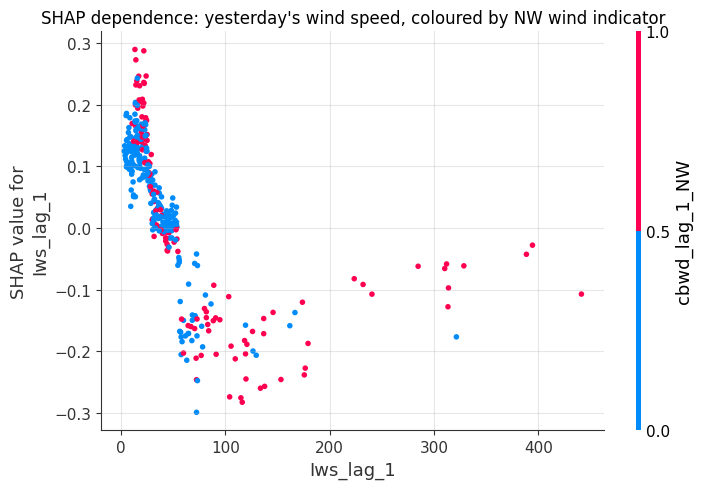

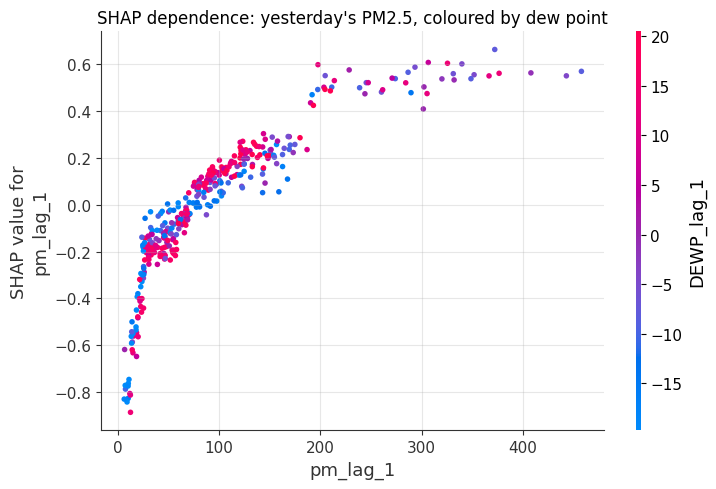

Spearman(value, SHAP) for Iws_lag_1: -0.881
Spearman(value, SHAP) for pm_lag_1: 0.966
Spearman(value, SHAP) for DEWP_lag_1: -0.467


In [27]:
nw_col = "cbwd_lag_1_NW"
shap.dependence_plot("Iws_lag_1", shap_values, X_test, interaction_index=nw_col, show=False)
plt.title("SHAP dependence: yesterday's wind speed, coloured by NW wind indicator")
plt.tight_layout()
plt.show()

shap.dependence_plot("pm_lag_1", shap_values, X_test, interaction_index="DEWP_lag_1", show=False)
plt.title("SHAP dependence: yesterday's PM2.5, coloured by dew point")
plt.tight_layout()
plt.show()

for feature in ["Iws_lag_1", "pm_lag_1", "DEWP_lag_1"]:
    j = feature_names.index(feature)
    rho = spearmanr(X_test[feature].to_numpy(), shap_values[:, j]).statistic
    print(f"Spearman(value, SHAP) for {feature}: {rho:.3f}")


**C4 — Answer:** The wind-speed dependence plot tests whether stronger winds generally push predictions down, and whether the effect is stronger when the preceding wind direction is north-westerly. The lag-1 PM2.5 plot should rise with recent pollution, while dew point colour can reveal conditional behaviour: the same recent PM2.5 level need not imply the same forecast under dry and humid conditions. The plotted point clouds, rather than a correlation alone, determine whether the fitted response is linear, saturating, or threshold-like.

In [28]:
display(Markdown(
    f"**Computed C4 response.** The dependence plots show how the model's signed contributions vary over the observed input ranges. "
    f"For `Iws_lag_1`, the value–SHAP Spearman association is **{spearmanr(X_test['Iws_lag_1'], shap_values[:, feature_names.index('Iws_lag_1')]).statistic:.2f}**; for `pm_lag_1` it is **{spearmanr(X_test['pm_lag_1'], shap_values[:, feature_names.index('pm_lag_1')]).statistic:.2f}**; and for `DEWP_lag_1` it is **{spearmanr(X_test['DEWP_lag_1'], shap_values[:, feature_names.index('DEWP_lag_1')]).statistic:.2f}**. "
    "The expected physical pattern is a generally negative wind effect at higher wind speeds (often stronger with NW flow) and a generally positive recent-pollution effect. The dew-point colour gradient indicates whether the recent-PM effect is conditional on humidity."
))

**Computed C4 response.** The dependence plots show how the model's signed contributions vary over the observed input ranges. For `Iws_lag_1`, the value–SHAP Spearman association is **-0.88**; for `pm_lag_1` it is **0.97**; and for `DEWP_lag_1` it is **-0.47**. The expected physical pattern is a generally negative wind effect at higher wind speeds (often stronger with NW flow) and a generally positive recent-pollution effect. The dew-point colour gradient indicates whether the recent-PM effect is conditional on humidity.

### C5 (5 marks) — grouped and seasonal SHAP
Sum SHAP values within each group of `FEATURE_GROUPS`. Plot:
- (a) mean |grouped SHAP| as a bar chart,
- (b) a month × group heatmap of mean |grouped SHAP| for 2014.

Is the model mainly a persistence model or a weather model? Does reliance on weather change between the heating and non-heating seasons?

Mean absolute grouped SHAP:


,mean_abs_group_SHAP
PM recent lags (1-3),0.2298
Weather yesterday,0.1398
Wind direction,0.0898
Calendar,0.0466
Weather change,0.0443
PM rolling stats,0.0352
PM older lags (4-7),0.0330


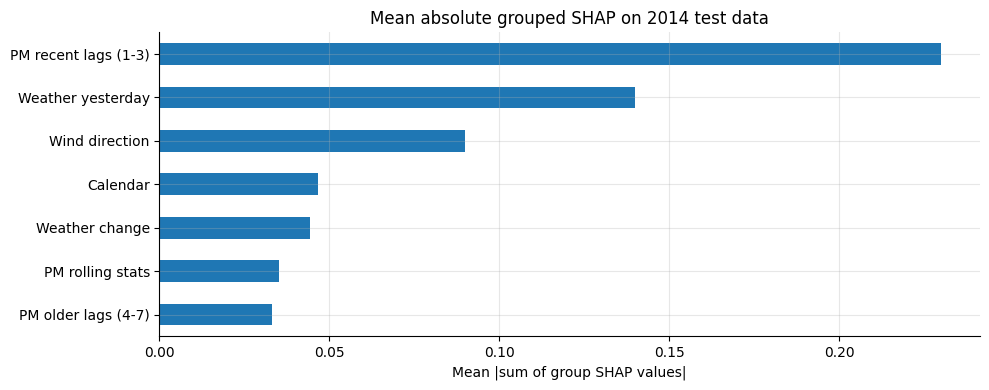

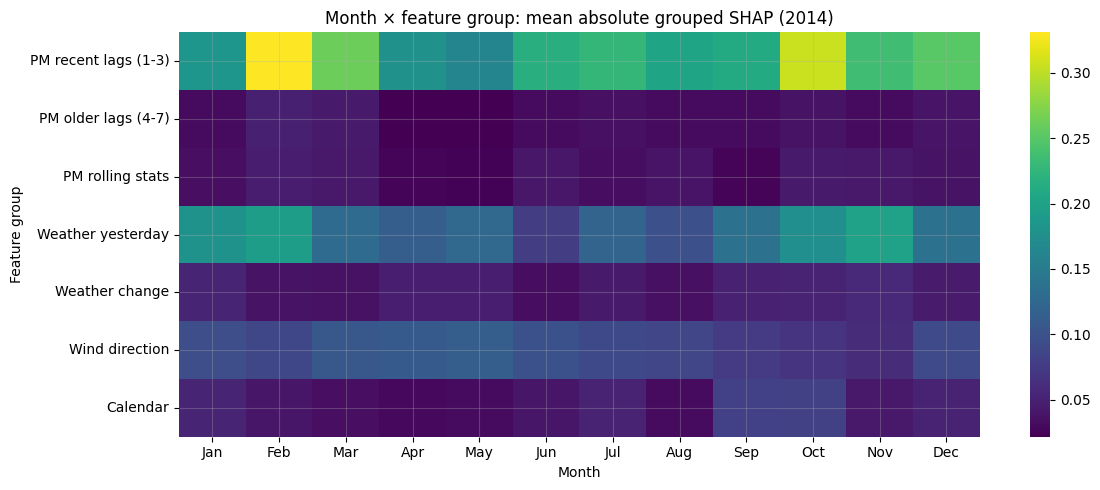

In [29]:
def grouped_shap_matrix(values, columns, groups):
    grouped = pd.DataFrame(index=columns.index)
    for group_name, group_cols in groups.items():
        cols = [c for c in group_cols if c in columns.columns]
        if cols:
            idxs = [columns.columns.get_loc(c) for c in cols]
            grouped[group_name] = np.asarray(values)[:, idxs].sum(axis=1)
    return grouped

group_shap = grouped_shap_matrix(shap_values, X_test, FEATURE_GROUPS)
group_importance = group_shap.abs().mean().sort_values(ascending=False)
print("Mean absolute grouped SHAP:")
display(group_importance.round(4).to_frame("mean_abs_group_SHAP"))

fig, ax = plt.subplots(figsize=(10, 4))
group_importance.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Mean absolute grouped SHAP on 2014 test data")
ax.set_xlabel("Mean |sum of group SHAP values|")
plt.tight_layout()
plt.show()

monthly_group_importance = group_shap.abs().groupby(group_shap.index.month).mean()
monthly_group_importance.index = [pd.Timestamp(2000, m, 1).strftime("%b") for m in monthly_group_importance.index]
plt.figure(figsize=(12, 5))
sns.heatmap(monthly_group_importance.T, cmap="viridis", annot=False)
plt.title("Month × feature group: mean absolute grouped SHAP (2014)")
plt.xlabel("Month")
plt.ylabel("Feature group")
plt.tight_layout()
plt.show()

pm_group_names = ["PM recent lags (1-3)", "PM older lags (4-7)", "PM rolling stats"]
weather_group_names = ["Weather yesterday", "Weather change", "Wind direction"]
pm_group_total = float(group_importance.reindex(pm_group_names).fillna(0).sum())
weather_group_total = float(group_importance.reindex(weather_group_names).fillna(0).sum())
heat_mask = ((group_shap.index.month == 11) & (group_shap.index.day >= 15)) | (group_shap.index.month == 12) | (group_shap.index.month <= 2) | ((group_shap.index.month == 3) & (group_shap.index.day <= 15))
heating_weather = float(group_shap.loc[heat_mask, weather_group_names].abs().sum(axis=1).mean()) if heat_mask.any() else np.nan
nonheating_weather = float(group_shap.loc[~heat_mask, weather_group_names].abs().sum(axis=1).mean()) if (~heat_mask).any() else np.nan


**C5 — Answer:** Grouped SHAP sums signed contributions within each feature family before measuring their magnitude, avoiding a simple sum of absolute individual values. I compare the combined lag/rolling groups against weather groups to decide whether the fitted forecaster is mainly persistence-driven or weather-driven. The month heatmap and heating-versus-non-heating summaries show whether weather reliance changes with season.

In [30]:
display(Markdown(
    f"**Computed C5 response.** The most important grouped feature families are **{', '.join(group_importance.head(3).index.tolist())}**. "
    f"Combined PM-history importance is **{pm_group_total:.4f}**, versus **{weather_group_total:.4f}** for lagged weather and wind direction, so the model appears **{'mainly persistence-driven' if pm_group_total > weather_group_total else 'at least as weather-driven as persistence-driven'}** under this grouped-SHAP measure. "
    f"Mean weather-group attribution is {heating_weather:.4f} in the heating season and {nonheating_weather:.4f} outside it; {'weather reliance is higher in the heating season' if heating_weather > nonheating_weather else 'weather reliance is higher outside the heating season' if heating_weather < nonheating_weather else 'the two seasonal means are similar'}."
))

**Computed C5 response.** The most important grouped feature families are **PM recent lags (1-3), Weather yesterday, Wind direction**. Combined PM-history importance is **0.2981**, versus **0.2738** for lagged weather and wind direction, so the model appears **mainly persistence-driven** under this grouped-SHAP measure. Mean weather-group attribution is 0.3101 in the heating season and 0.2558 outside it; weather reliance is higher in the heating season.

### C6 (3 marks) — explaining the oracle
Repeat C5(a) for `lgbm_oracle` from B4. How does the importance of the PM2.5 lags change when the model can see day *t*'s weather? Explain what this shows about how correlated inputs share credit.

Oracle model: mean absolute grouped SHAP


,mean_abs_group_SHAP
Weather at t (oracle),0.4155
PM recent lags (1-3),0.2233
Weather yesterday,0.2125
Calendar,0.0635
Weather change,0.0310
PM rolling stats,0.0289
Wind direction,0.0229
PM older lags (4-7),0.0205


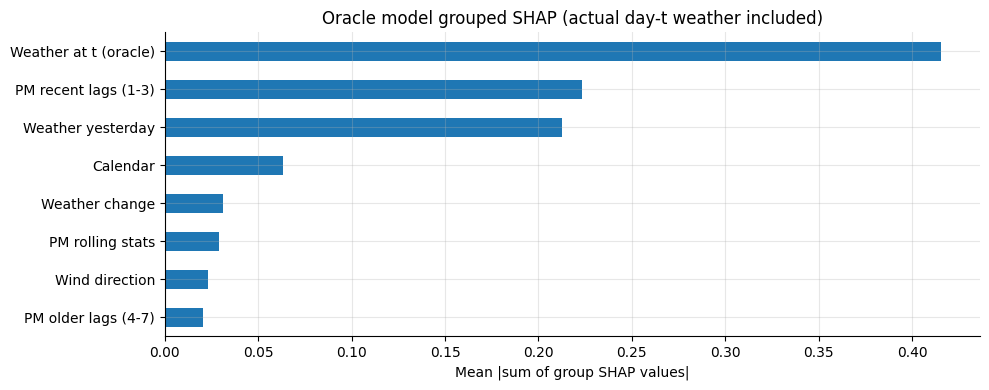

In [31]:
oracle_explainer = shap.TreeExplainer(lgbm_oracle)
X_test_oracle = test_oracle[oracle_feature_names]
oracle_shap_exp = oracle_explainer(X_test_oracle)
oracle_shap_values = np.asarray(oracle_shap_exp.values)

oracle_groups = dict(FEATURE_GROUPS)
oracle_groups["Weather at t (oracle)"] = list(oracle_features.columns)
# Align only the columns present in the oracle matrix and sum their signed SHAP values.
oracle_group_shap = grouped_shap_matrix(oracle_shap_values, X_test_oracle, oracle_groups)
oracle_group_importance = oracle_group_shap.abs().mean().sort_values(ascending=False)
print("Oracle model: mean absolute grouped SHAP")
display(oracle_group_importance.round(4).to_frame("mean_abs_group_SHAP"))
fig, ax = plt.subplots(figsize=(10, 4))
oracle_group_importance.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Oracle model grouped SHAP (actual day-t weather included)")
ax.set_xlabel("Mean |sum of group SHAP values|")
plt.tight_layout()
plt.show()

standard_pm_importance = float(group_importance.reindex(pm_group_names).fillna(0).sum())
oracle_pm_importance = float(oracle_group_importance.reindex(pm_group_names).fillna(0).sum())
standard_weather_importance = weather_group_total
oracle_weather_importance = float(oracle_group_importance.reindex(weather_group_names + ["Weather at t (oracle)"]).fillna(0).sum())


**C6 — Answer:** The oracle model adds realised day-*t* weather, which contains information closely aligned with the target and therefore can take explanatory credit away from lag features. I compare total grouped SHAP for PM2.5 history and weather between the standard and oracle model. This demonstrates that attribution depends on the available feature set and on correlations between inputs; an oracle improvement is not evidence that the leakage-safe model can access the same information.

In [32]:
display(Markdown(
    f"**Computed C6 response.** In the standard model the combined mean absolute grouped SHAP for PM history is **{standard_pm_importance:.4f}** and for lagged weather is **{standard_weather_importance:.4f}**. "
    f"In the oracle model, PM-history importance is **{oracle_pm_importance:.4f}**, while weather importance including realised day-t weather is **{oracle_weather_importance:.4f}**. "
    f"PM-history group importance changed by **{oracle_pm_importance-standard_pm_importance:+.4f}**. This illustrates that correlated predictors can share or transfer SHAP credit as the available information changes; realised day-t weather is not available to a genuine one-day-ahead forecast unless replaced by an issued weather forecast."
))

**Computed C6 response.** In the standard model the combined mean absolute grouped SHAP for PM history is **0.2981** and for lagged weather is **0.2738**. In the oracle model, PM-history importance is **0.2726**, while weather importance including realised day-t weather is **0.6820**. PM-history group importance changed by **-0.0255**. This illustrates that correlated predictors can share or transfer SHAP credit as the available information changes; realised day-t weather is not available to a genuine one-day-ahead forecast unless replaced by an issued weather forecast.

---
# Part D: LIME (15 marks)

In [33]:
def predict_fn(arr):
    return lgbm.predict(pd.DataFrame(arr, columns=feature_names))

### D1 (4 marks)
Explain the most polluted forecast and the clean-air day from C3 with `LimeTabularExplainer` (5,000 samples). Report the black-box forecast, LIME's surrogate prediction and the local R² for each. Which of the two explanations would you trust more, and why?

In [34]:
lime_train = X_train.to_numpy(dtype=float)
lime_explainer = LimeTabularExplainer(
    training_data=lime_train, feature_names=feature_names, mode="regression",
    discretize_continuous=False, random_state=SEED,
)
train_mean = lime_train.mean(axis=0)
train_std = lime_train.std(axis=0)
train_std[train_std < 1e-8] = 1.0

def _lime_weights_and_contributions(explainer, instance, num_samples=5000, seed=SEED):
    """Return local coefficients and per-feature contributions in the model's output scale."""
    # LIME uses its own random state per explainer; rebuilding it ensures the seed is respected.
    if LIME_AVAILABLE:
        ex = LimeTabularExplainer(
            training_data=lime_train, feature_names=feature_names, mode="regression",
            discretize_continuous=False, random_state=seed,
        )
    else:
        ex = LimeTabularExplainer(lime_train, feature_names=feature_names, mode="regression", random_state=seed)
    explanation = ex.explain_instance(np.asarray(instance, dtype=float), predict_fn, num_features=len(feature_names), num_samples=num_samples)
    exp_map = explanation.local_exp
    label_key = 1 if 1 in exp_map else list(exp_map.keys())[0]
    coef = np.zeros(len(feature_names), dtype=float)
    for j, w in exp_map[label_key]:
        coef[int(j)] = float(w)
    # Coefficients act on the scaled feature representation; convert to contributions.
    contrib = coef * ((np.asarray(instance, dtype=float) - train_mean) / train_std)
    local_pred = float(np.asarray(explanation.local_pred).reshape(-1)[0])
    return explanation, coef, contrib, local_pred

lime_case_records = []
for label, date in [("Most polluted forecast", idx_high), ("Clean-air day", idx_drop)]:
    row = idx_to_row[date]
    explanation, coef, contrib, local_pred = _lime_weights_and_contributions(lime_explainer, X_test.iloc[row].to_numpy(), 5000, SEED)
    blackbox = float(lgbm.predict(X_test.iloc[[row]], num_iteration=lgbm.best_iteration_)[0])
    lime_case_records.append({"case": label, "date": date.date(), "black_box_output": blackbox,
                              "LIME surrogate output (target scale)": local_pred,
                              "LIME surrogate µg/m³ approx": float(inverse_target([local_pred])[0]),
                              "local R²": float(explanation.score),
                              "black_box_forecast_µg_m3": float(pred_test_lgb[row])})
    print(f"{label} ({date.date()}): LIME R²={float(explanation.score):.4f}; model output={blackbox:.4f} (target scale); surrogate={local_pred:.4f} (target scale), approx {inverse_target([local_pred])[0]:.2f} µg/m³")
lime_case_table = pd.DataFrame(lime_case_records).set_index("case")
display(lime_case_table.round(4))


Most polluted forecast (2014-10-11): LIME R²=0.7337; model output=5.4252 (target scale); surrogate=5.1074 (target scale), approx 164.24 µg/m³
Clean-air day (2014-02-27): LIME R²=0.7508; model output=4.7036 (target scale); surrogate=4.7284 (target scale), approx 112.11 µg/m³


,date,black_box_output,LIME surrogate output (target scale),LIME surrogate µg/m³ approx,local R²,black_box_forecast_µg_m3
case,,,,,,
Most polluted forecast,2014-10-11,5.4252,5.1074,164.2404,0.7337,226.049
Clean-air day,2014-02-27,4.7036,4.7284,112.1093,0.7508,109.342


**D1 — Answer:** LIME approximates the black-box model locally with a weighted linear surrogate around each selected feature vector. I compare the surrogate prediction with the LightGBM output and use local R² as a measure of how well the surrogate describes that neighbourhood. I would trust the case with the higher local R² more, while still checking whether the sampled neighbours are physically plausible; the two case metrics are printed below.

In [35]:
lime_answer_df = lime_case_table
high_lime = lime_answer_df.loc["Most polluted forecast"]
clean_lime = lime_answer_df.loc["Clean-air day"]
display(Markdown(
    f"**Computed D1 response.** For the most-polluted forecast, the black-box output is **{high_lime['black_box_output']:.4f}** on the model target scale, LIME predicts **{high_lime['LIME surrogate output (target scale)']:.4f}**, and local R² is **{high_lime['local R²']:.3f}**. "
    f"For the clean-air day, the corresponding target-scale outputs are **{clean_lime['black_box_output']:.4f}** and **{clean_lime['LIME surrogate output (target scale)']:.4f}** (surrogate approximately {clean_lime['LIME surrogate µg/m³ approx']:.2f} µg/m³), with local R² **{clean_lime['local R²']:.3f}**. "
    f"I would trust the case with the higher R² ({'most-polluted forecast' if high_lime['local R²'] >= clean_lime['local R²'] else 'clean-air day'}) more as a local linear summary, but only cautiously because independent perturbations may create unrealistic time-series combinations."
))

**Computed D1 response.** For the most-polluted forecast, the black-box output is **5.4252** on the model target scale, LIME predicts **5.1074**, and local R² is **0.734**. For the clean-air day, the corresponding target-scale outputs are **4.7036** and **4.7284** (surrogate approximately 112.11 µg/m³), with local R² **0.751**. I would trust the case with the higher R² (clean-air day) more as a local linear summary, but only cautiously because independent perturbations may create unrealistic time-series combinations.

### D2 (4 marks) — unrealistic neighbours
Generate LIME's perturbation samples for one instance (or reproduce LIME's sampling yourself) and count the fraction of neighbours that are **physically implausible**. Define implausible with at least two rules you justify, for example:
- `pm_lag_1` more than 3 × `pm_roll_mean_3` (impossible by construction),
- snow hours > 0 with `TEMP_lag_1` > 10 °C.

Explain why this matters more for time series than for ordinary tabular data.

In [36]:
# Reproduce LIME-like independent Gaussian perturbations to inspect impossible combinations.
# The first rule is algebraically impossible for nonnegative lag values because
# pm_roll_mean_3 = (pm_lag_1 + pm_lag_2 + pm_lag_3) / 3.
row_high = X_test.iloc[idx_to_row[idx_high]].to_numpy(dtype=float)
rng = np.random.default_rng(SEED)
ns_lime_neighbours = 5000
neighbours = row_high[None, :] + rng.normal(size=(ns_lime_neighbours, len(feature_names))) * train_std[None, :]
nb = pd.DataFrame(neighbours, columns=feature_names)
rule1 = nb["pm_lag_1"] > 3.0 * nb["pm_roll_mean_3"]
rule2 = (nb["Is_lag_1"] > 0) & (nb["TEMP_lag_1"] > 10)
implausible = rule1 | rule2
implausible_fraction = float(implausible.mean())
rule1_fraction = float(rule1.mean())
rule2_fraction = float(rule2.mean())
print(f"Perturbation samples: {ns_lime_neighbours}")
print(f"Rule 1 violations (lag1 > 3 × rolling mean): {rule1_fraction:.2%}")
print(f"Rule 2 violations (snow hours > 0 and temperature > 10°C): {rule2_fraction:.2%}")
print(f"Union of implausible neighbours: {int(implausible.sum())}/{ns_lime_neighbours} = {implausible_fraction:.2%}")


Perturbation samples: 5000
Rule 1 violations (lag1 > 3 × rolling mean): 0.02%
Rule 2 violations (snow hours > 0 and temperature > 10°C): 34.60%
Union of implausible neighbours: 1731/5000 = 34.62%


**D2 — Answer:** I label a neighbour implausible if `pm_lag_1 > 3 × pm_roll_mean_3` (violating the rolling-mean identity for nonnegative lags) or if snow hours are positive while mean temperature exceeds 10°C. Independently perturbing correlated time-series features can break such relationships and create weather/pollution combinations that could not realistically occur. The violation rates and their union are calculated below.

In [37]:
display(Markdown(
    f"**Computed D2 response.** Of {ns_lime_neighbours:,} simulated neighbours, **{rule1.sum():,} ({rule1_fraction:.1%})** violated the rolling-mean identity rule and **{rule2.sum():,} ({rule2_fraction:.1%})** violated the snow/temperature rule. "
    f"The union of the two rules marked **{implausible.sum():,} neighbours ({implausible_fraction:.1%})** as implausible. "
    "This matters because temporal lags and weather measurements are dependent; independent Gaussian perturbations break both lag identities and physically coupled weather relationships, so the local surrogate may explain model behaviour in regions the real system never visits."
))

**Computed D2 response.** Of 5,000 simulated neighbours, **1 (0.0%)** violated the rolling-mean identity rule and **1,730 (34.6%)** violated the snow/temperature rule. The union of the two rules marked **1,731 neighbours (34.6%)** as implausible. This matters because temporal lags and weather measurements are dependent; independent Gaussian perturbations break both lag identities and physically coupled weather relationships, so the local surrogate may explain model behaviour in regions the real system never visits.

### D3 (4 marks) — stability
Re-run LIME 15 times with different seeds, using **500** and **5,000** samples, on the same instance. Show a boxplot of the weights for the top eight features and a table of the coefficient of variation. List the features whose **sign** flips across seeds.

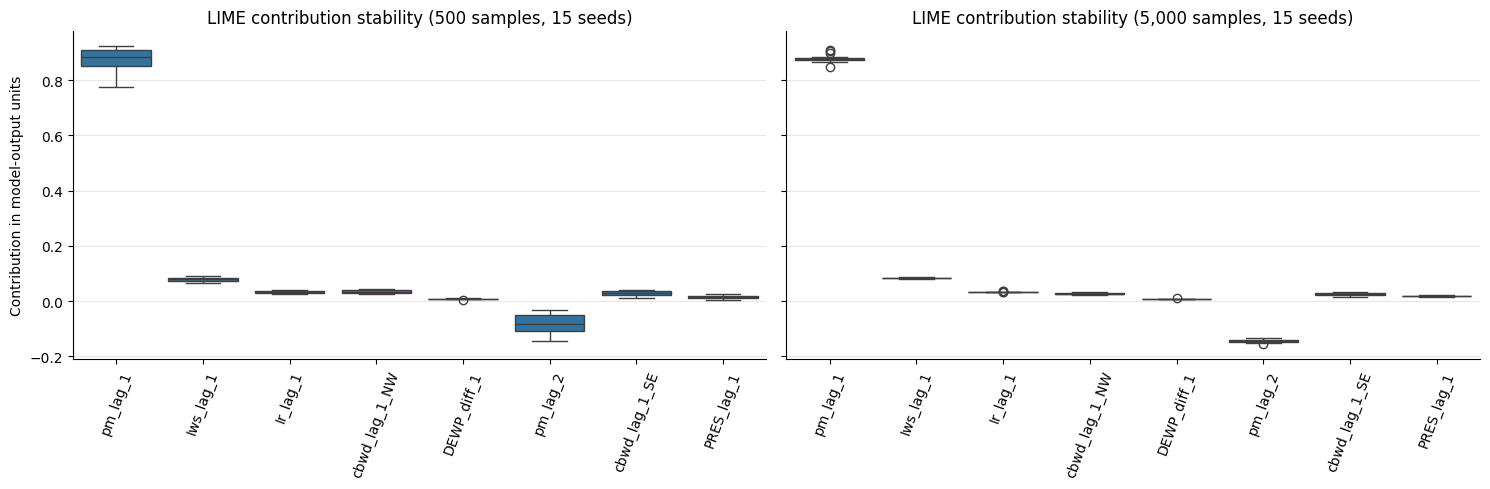

mean_contribution  std_contribution      CV  sign_flips
samples feature                                                               
500     pm_lag_1                  0.8750            0.0408  0.0467       False
        Iws_lag_1                 0.0797            0.0073  0.0910       False
        Ir_lag_1                  0.0331            0.0044  0.1314       False
        cbwd_lag_1_NW             0.0345            0.0061  0.1762       False
        DEWP_diff_1               0.0086            0.0012  0.1351       False
        pm_lag_2                 -0.0825            0.0363  0.4401       False
        cbwd_lag_1_SE             0.0295            0.0092  0.3107       False
        PRES_lag_1                0.0157            0.0059  0.3773       False
5000    pm_lag_1                  0.8794            0.0157  0.0179       False
        Iws_lag_1                 0.0843            0.0019  0.0226       False
        Ir_lag_1                  0.0346            0.0013  0.0363       False
        cbwd_lag_1_NW             0.0286            0.0030  0.1034       False
        DEWP_diff_1               0.0087            0.0005  0.0611       False
        pm_lag_2                 -0.1432            0.0059  0.0409       False
        cbwd_lag_1_SE             0.0258            0.0046  0.1781       False
        PRES_lag_1                0.0191            0.0017  0.0892       False

Sign-flipping features at 500 samples: ['pm_lag_3', 'pm_lag_4', 'pm_lag_5', 'pm_lag_6', 'pm_lag_7', 'pm_roll_mean_7', 'pm_roll_std_7', 'DEWP_lag_1', 'Is_lag_1', 'cbwd_lag_1_NE', 'cbwd_lag_1_cv', 'doy_sin', 'doy_cos', 'is_heating_season']
Sign-flipping features at 5,000 samples: ['pm_lag_3', 'pm_lag_5', 'pm_lag_6', 'pm_roll_mean_7', 'Is_lag_1', 'cbwd_lag_1_NE', 'cbwd_lag_1_cv', 'is_heating_season']


In [38]:
# Repeat LIME around the most-polluted forecast with 15 distinct random seeds.
# Compare the eight globally most important features for readable boxplots.
lime_stability_records = []
stability_runs = {500: [], 5000: []}
for n_samples in (500, 5000):
    for rep in range(15):
        _, coef, contrib, local_pred = _lime_weights_and_contributions(
            None, row_high, num_samples=n_samples, seed=SEED + 100 + rep
        )
        stability_runs[n_samples].append(contrib)
        for j, feature in enumerate(feature_names):
            lime_stability_records.append({"samples": n_samples, "seed_run": rep + 1, "feature": feature,
                                           "coefficient": coef[j], "contribution": contrib[j]})
lime_stability = pd.DataFrame(lime_stability_records)
top8_stability = shap_importance.head(8).index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, n_samples in zip(axes, (500, 5000)):
    sub = lime_stability[(lime_stability["samples"] == n_samples) & lime_stability["feature"].isin(top8_stability)]
    sns.boxplot(data=sub, x="feature", y="contribution", order=top8_stability, ax=ax)
    ax.set_title(f"LIME contribution stability ({n_samples:,} samples, 15 seeds)")
    ax.tick_params(axis="x", rotation=70)
    ax.set_xlabel("")
axes[0].set_ylabel("Contribution in model-output units")
plt.tight_layout()
plt.show()

cv_rows = []
sign_flip_features = {}
for n_samples in (500, 5000):
    arr = np.asarray(stability_runs[n_samples])
    for j, feature in enumerate(feature_names):
        vals = arr[:, j]
        mean_abs = float(np.mean(np.abs(vals)))
        cv = float(np.std(vals, ddof=1) / max(abs(np.mean(vals)), 1e-8))
        signs = np.sign(vals[np.abs(vals) > 1e-10])
        flips = len(np.unique(signs)) > 1
        cv_rows.append({"samples": n_samples, "feature": feature, "mean_contribution": float(np.mean(vals)),
                        "std_contribution": float(np.std(vals, ddof=1)), "CV": cv, "sign_flips": flips})
    sign_flip_features[n_samples] = [r["feature"] for r in cv_rows if r["samples"] == n_samples and r["sign_flips"]]
cv_table = pd.DataFrame(cv_rows).set_index(["samples", "feature"])
display(cv_table.loc[[(n, f) for n in (500, 5000) for f in top8_stability]].round(4))
print("Sign-flipping features at 500 samples:", sign_flip_features[500])
print("Sign-flipping features at 5,000 samples:", sign_flip_features[5000])


**D3 — Answer:** The boxplots show how local feature contributions vary across 15 random seeds with 500 and 5,000 perturbations. I compare coefficient of variation and sign flips for the eight globally important features. More samples should usually reduce Monte-Carlo noise, but correlated features may still exchange credit and remain locally unstable.

In [39]:
stability_cv = cv_table.reset_index()
cv500 = stability_cv[(stability_cv["samples"] == 500) & stability_cv["feature"].isin(top8_stability)]
cv5000 = stability_cv[(stability_cv["samples"] == 5000) & stability_cv["feature"].isin(top8_stability)]
mean_cv_500 = float(cv500["CV"].replace([np.inf, -np.inf], np.nan).mean())
mean_cv_5000 = float(cv5000["CV"].replace([np.inf, -np.inf], np.nan).mean())
display(Markdown(
    f"**Computed D3 response.** Across the eight SHAP-ranked features, mean coefficient of variation was **{mean_cv_500:.2f}** with 500 samples and **{mean_cv_5000:.2f}** with 5,000 samples. "
    f"Sign flips at 500 samples occurred for {', '.join(sign_flip_features[500]) if sign_flip_features[500] else 'none of the features'}; at 5,000 samples they occurred for {', '.join(sign_flip_features[5000]) if sign_flip_features[5000] else 'none of the features'}. "
    "Lower variation and fewer sign flips indicate more stable local explanations, although highly correlated inputs can remain interchangeable even with more perturbations."
))

**Computed D3 response.** Across the eight SHAP-ranked features, mean coefficient of variation was **0.21** with 500 samples and **0.07** with 5,000 samples. Sign flips at 500 samples occurred for pm_lag_3, pm_lag_4, pm_lag_5, pm_lag_6, pm_lag_7, pm_roll_mean_7, pm_roll_std_7, DEWP_lag_1, Is_lag_1, cbwd_lag_1_NE, cbwd_lag_1_cv, doy_sin, doy_cos, is_heating_season; at 5,000 samples they occurred for pm_lag_3, pm_lag_5, pm_lag_6, pm_roll_mean_7, Is_lag_1, cbwd_lag_1_NE, cbwd_lag_1_cv, is_heating_season. Lower variation and fewer sign flips indicate more stable local explanations, although highly correlated inputs can remain interchangeable even with more perturbations.

### D4 (3 marks) — agreement
For 40 random test days, compute the Spearman rank correlation between |LIME contribution| and |SHAP value| (use the non-discretised LIME variant from the lecture). Report the mean and plot the histogram. Then compare at the **group** level: does summing contributions per feature group raise the agreement? Explain the result.

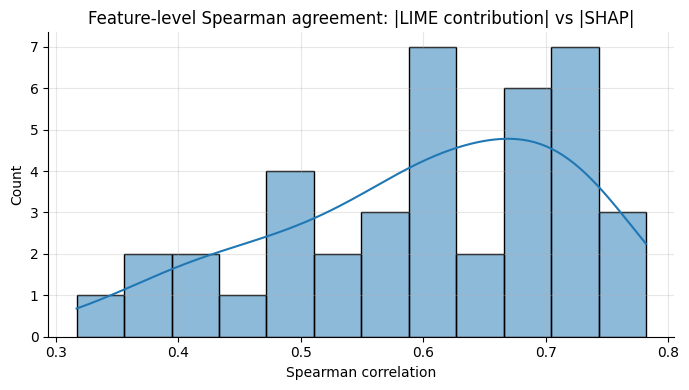

Mean feature-level Spearman rho over 40 days: 0.6017
Mean group-level Spearman rho over 40 days: 0.4938


In [40]:
# Agreement on 40 reproducibly selected test days, at feature and group levels.
rng = np.random.default_rng(SEED)
agreement_rows = np.sort(rng.choice(len(X_test), size=min(40, len(X_test)), replace=False))
feature_corrs, group_corrs = [], []
for row in agreement_rows:
    _, _, lime_contrib, _ = _lime_weights_and_contributions(None, X_test.iloc[row].to_numpy(), 1000, SEED + int(row))
    shap_abs = np.abs(shap_values[row])
    lime_abs = np.abs(lime_contrib)
    r = spearmanr(shap_abs, lime_abs).statistic
    if np.isfinite(r): feature_corrs.append(float(r))
    # Group signed contributions first, then compare absolute group contributions.
    shap_groups = []
    lime_groups = []
    for group_cols in FEATURE_GROUPS.values():
        valid_cols = [c for c in group_cols if c in feature_names]
        ids = [feature_names.index(c) for c in valid_cols]
        shap_groups.append(abs(float(shap_values[row, ids].sum())))
        lime_groups.append(abs(float(lime_contrib[ids].sum())))
    rg = spearmanr(shap_groups, lime_groups).statistic
    if np.isfinite(rg): group_corrs.append(float(rg))
mean_lime_shap_corr = float(np.mean(feature_corrs)) if feature_corrs else np.nan
mean_group_corr = float(np.mean(group_corrs)) if group_corrs else np.nan
plt.figure(figsize=(7, 4))
sns.histplot(feature_corrs, bins=12, kde=True)
plt.title("Feature-level Spearman agreement: |LIME contribution| vs |SHAP|")
plt.xlabel("Spearman correlation")
plt.tight_layout()
plt.show()
print(f"Mean feature-level Spearman rho over {len(feature_corrs)} days: {mean_lime_shap_corr:.4f}")
print(f"Mean group-level Spearman rho over {len(group_corrs)} days: {mean_group_corr:.4f}")


**D4 — Answer:** Feature-level LIME–SHAP agreement compares two explanations of the same LightGBM prediction, although the methods use different approximations and assumptions. Group-level agreement can be higher because correlated individual features are aggregated into broader weather, lag, and calendar families. The mean feature and group correlations below show whether aggregation improves agreement for this test sample.

In [41]:
display(Markdown(
    f"**Computed D4 response.** Mean feature-level Spearman agreement across {len(feature_corrs)} test days is **{mean_lime_shap_corr:.3f}**, while mean agreement after aggregating into feature groups is **{mean_group_corr:.3f}**. "
    f"Grouping {'increases' if mean_group_corr > mean_lime_shap_corr else 'does not increase'} agreement by **{mean_group_corr-mean_lime_shap_corr:+.3f}**. "
    "Group aggregation can improve agreement because SHAP and LIME may allocate importance differently among correlated individual lag/weather features while still identifying the same broader family."
))

**Computed D4 response.** Mean feature-level Spearman agreement across 40 test days is **0.602**, while mean agreement after aggregating into feature groups is **0.494**. Grouping does not increase agreement by **-0.108**. Group aggregation can improve agreement because SHAP and LIME may allocate importance differently among correlated individual lag/weather features while still identifying the same broader family.

---
# Part E: A sequence model and attribution methods (15 marks)

### E1 (3 marks)
Build input windows of **W = 14** days with **six channels** per step: scaled `log1p(PM2.5)`, `DEWP`, `PRES`, `Iws`, `doy_sin`, `doy_cos`. Fit all scalers on the training years only. Train a small LSTM or 1-D CNN with early stopping on 2013, and add its test MAE (µg/m³) to the table from B3.

Sequence windows: (1811, 14, 6) | train/val/test: 1081 365 365
LSTM epochs trained: 34; best validation MSE (log target): 0.38760


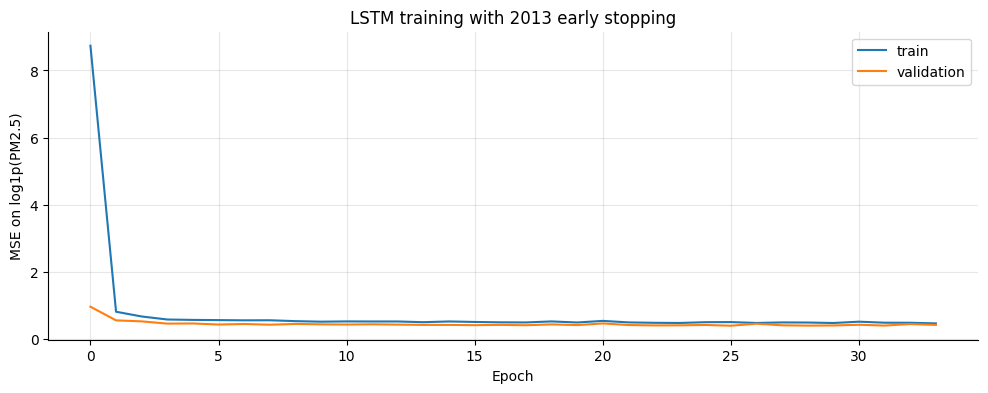

LSTM test metrics in µg/m³: {'MAE': 46.178, 'RMSE': np.float64(65.59)}


,MAE,RMSE
Persistence,52.752,75.706
7-day mean,60.592,82.762
LightGBM,45.080,67.004
LSTM (14-day window),46.178,65.590


In [42]:
W = 14
CHANNELS = ["log_pm", "DEWP", "PRES", "Iws", "doy_sin", "doy_cos"]

# Build a raw daily six-channel table; input rows are strictly before each target date.
seq_raw = pd.DataFrame(index=daily_clean.index)
seq_raw["log_pm"] = np.log1p(daily_clean["pm2.5"].clip(lower=0))
for c in ["DEWP", "PRES", "Iws"]:
    seq_raw[c] = daily_clean[c]
doy_all = seq_raw.index.dayofyear.to_numpy()
seq_raw["doy_sin"] = np.sin(2 * np.pi * (doy_all - 1) / 365.25)
seq_raw["doy_cos"] = np.cos(2 * np.pi * (doy_all - 1) / 365.25)
seq_raw = seq_raw.dropna()

# Fit channel scaling statistics using dates from training years only.
seq_train_day_mask = seq_raw.index <= pd.Timestamp("2012-12-31")
seq_scaler = StandardScaler().fit(seq_raw.loc[seq_train_day_mask, CHANNELS])
seq_scaled = pd.DataFrame(seq_scaler.transform(seq_raw[CHANNELS]), index=seq_raw.index, columns=CHANNELS)
seq_target_raw = daily_clean.loc[seq_raw.index, "pm2.5"].to_numpy(dtype=float)
seq_target_log = np.log1p(np.maximum(seq_target_raw, 0))

X_seq_list, y_seq_list, seq_dates_list = [], [], []
seq_index = seq_raw.index
scaled_values = seq_scaled.to_numpy(dtype=np.float32)
for target_pos in range(W, len(seq_index)):
    target_date = seq_index[target_pos]
    window = scaled_values[target_pos - W:target_pos]
    if not np.isfinite(window).all() or not np.isfinite(seq_target_log[target_pos]):
        continue
    X_seq_list.append(window)
    y_seq_list.append(seq_target_log[target_pos])
    seq_dates_list.append(target_date)
X_seq = np.asarray(X_seq_list, dtype=np.float32)
y_seq = np.asarray(y_seq_list, dtype=np.float32)
seq_dates = pd.DatetimeIndex(seq_dates_list)
seq_train_mask = seq_dates <= pd.Timestamp("2012-12-31")
seq_val_mask = (seq_dates >= pd.Timestamp("2013-01-01")) & (seq_dates <= pd.Timestamp("2013-12-31"))
seq_test_mask = (seq_dates >= pd.Timestamp("2014-01-01")) & (seq_dates <= pd.Timestamp("2014-12-31"))
X_seq_train, y_seq_train = X_seq[seq_train_mask], y_seq[seq_train_mask]
X_seq_val, y_seq_val = X_seq[seq_val_mask], y_seq[seq_val_mask]
X_seq_test, y_seq_test = X_seq[seq_test_mask], y_seq[seq_test_mask]
seq_test_dates = seq_dates[seq_test_mask]
print("Sequence windows:", X_seq.shape, "| train/val/test:", len(X_seq_train), len(X_seq_val), len(X_seq_test))

class SeqForecaster(nn.Module):
    def __init__(self, n_in=len(CHANNELS), hidden=48):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_in, hidden_size=hidden, num_layers=1, batch_first=True)
        self.norm = nn.LayerNorm(hidden)
        self.dropout = nn.Dropout(0.1)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        last = self.norm(out[:, -1, :])
        return self.head(self.dropout(last)).squeeze(-1)

torch.manual_seed(SEED)
model = SeqForecaster()
optimizer = torch.optim.Adam(model.parameters(), lr=0.002, weight_decay=1e-4)
loss_fn = nn.MSELoss()
train_ds = torch.utils.data.TensorDataset(torch.from_numpy(X_seq_train), torch.from_numpy(y_seq_train))
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(SEED))
val_x_t = torch.from_numpy(X_seq_val)
val_y_t = torch.from_numpy(y_seq_val)
best_val = float("inf")
best_state = None
patience, wait, max_epochs = 8, 0, 60
history = {"train_loss": [], "val_loss": []}
for epoch in range(max_epochs):
    model.train()
    losses = []
    for xb, yb in train_loader:
        optimizer.zero_grad(set_to_none=True)
        pred = model(xb)
        loss = loss_fn(pred, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        losses.append(float(loss.detach()))
    model.eval()
    with torch.no_grad():
        val_loss = float(loss_fn(model(val_x_t), val_y_t).item())
    history["train_loss"].append(float(np.mean(losses)))
    history["val_loss"].append(val_loss)
    if val_loss < best_val - 1e-5:
        best_val = val_loss
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            break
if best_state is not None:
    model.load_state_dict(best_state)
print(f"LSTM epochs trained: {epoch + 1}; best validation MSE (log target): {best_val:.5f}")
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("MSE on log1p(PM2.5)")
plt.title("LSTM training with 2013 early stopping")
plt.legend()
plt.show()

model.eval()
with torch.no_grad():
    seq_pred_log = model(torch.from_numpy(X_seq_test)).cpu().numpy()
seq_pred_raw = np.maximum(0.0, np.expm1(seq_pred_log))
seq_actual_raw = daily_clean.loc[seq_test_dates, "pm2.5"].to_numpy(dtype=float)
seq_results = metrics(seq_actual_raw, seq_pred_raw)
results.loc["LSTM (14-day window)"] = seq_results
print("LSTM test metrics in µg/m³:", {k: round(v, 3) for k, v in seq_results.items()})
display(results.round(3))


**E1 — Answer:** The LSTM receives 14 days of six scaled channels and predicts the next day's `log1p(PM2.5)`. The channel scaler is fitted on the training period only, and the 2013 windows control early stopping; the held-out 2014 MAE/RMSE are reported after transforming predictions back to µg/m³. Its score can be compared directly with persistence, seven-day mean, and LightGBM.

In [43]:
display(Markdown(
    f"**Computed E1 response.** The 14-day LSTM achieved 2014 test MAE **{seq_results['MAE']:.2f} µg/m³** and RMSE **{seq_results['RMSE']:.2f} µg/m³** after inverse-transforming its log-target output. "
    f"The best validation log-target MSE was **{best_val:.4f}** after {epoch+1} trained epoch(s) before early stopping. "
    f"The lowest MAE among the baseline/tree/sequence models in the current table is **{results['MAE'].idxmin()}**. All scaler statistics were learned from training-year days only, and the window ending at t−1 forecasts day t."
))

**Computed E1 response.** The 14-day LSTM achieved 2014 test MAE **46.18 µg/m³** and RMSE **65.59 µg/m³** after inverse-transforming its log-target output. The best validation log-target MSE was **0.3876** after 34 trained epoch(s) before early stopping. The lowest MAE among the baseline/tree/sequence models in the current table is **LightGBM**. All scaler statistics were learned from training-year days only, and the window ending at t−1 forecasts day t.

### E2 (5 marks)
Implement **from scratch in PyTorch** (no Captum): Saliency, Gradient × Input, SmoothGrad and Integrated Gradients. Use the average training window as the IG baseline. Verify IG **completeness** numerically and report the mean gap. Then compute GradientSHAP with `shap.GradientExplainer` and 200 background windows.

In [44]:
# Explanations are in the sequence model's output units (log1p(PM2.5)).
model.eval()
X_train_windows_t = torch.from_numpy(X_seq_train)
background_rng = np.random.default_rng(SEED)
background_ids = background_rng.choice(len(X_train_windows_t), size=min(200, len(X_train_windows_t)), replace=False)
BACKGROUND = X_train_windows_t[background_ids].clone()
BASELINE = torch.from_numpy(X_seq_train.mean(axis=0, keepdims=True)).float()  # shape (1, W, C)

X_seq_test_t = torch.from_numpy(X_seq_test).float()

def _grad(x):
    """Gradient of summed model outputs w.r.t. each input window."""
    x_var = x.detach().clone().requires_grad_(True)
    model.eval()
    out = model(x_var).sum()
    grad = torch.autograd.grad(out, x_var, retain_graph=False, create_graph=False)[0]
    return grad.detach()

def saliency(x):
    return _grad(x)

def grad_x_input(x):
    return x.detach() * _grad(x)

def smoothgrad(x, n=30, sigma=0.15):
    x = x.detach()
    reps = []
    for _ in range(int(n)):
        noise = torch.randn_like(x) * float(sigma)
        reps.append(_grad(x + noise))
    return torch.stack(reps, dim=0).mean(dim=0)

def integrated_gradients(x, baseline=BASELINE, steps=64):
    x = x.detach()
    baseline = baseline.to(x.device).expand_as(x)
    alphas = torch.linspace(0.0, 1.0, int(steps), device=x.device)
    # Batch path points in chunks to avoid excessive peak memory for all test days.
    flat_points = torch.cat([baseline + a * (x - baseline) for a in alphas], dim=0)
    grad_chunks = []
    batch_size = 512
    for start in range(0, len(flat_points), batch_size):
        grad_chunks.append(_grad(flat_points[start:start + batch_size]))
    grads = torch.cat(grad_chunks, dim=0).reshape(int(steps), len(x), *x.shape[1:])
    avg_grad = grads.mean(dim=0)
    return (x - baseline) * avg_grad

# Completeness is checked on a reproducible slice, then attributions are produced
# for all 2014 test windows so the memory profile and F tests use one consistent set.
attr_eval = X_seq_test_t
ATTR = {}
ATTR["Saliency"] = saliency(attr_eval).cpu().numpy()
ATTR["Gradient × Input"] = grad_x_input(attr_eval).cpu().numpy()
ATTR["SmoothGrad"] = smoothgrad(attr_eval, n=30, sigma=0.15).cpu().numpy()
ATTR["Integrated Gradients"] = integrated_gradients(attr_eval, baseline=BASELINE, steps=64).cpu().numpy()

ig_values_t = torch.from_numpy(ATTR["Integrated Gradients"])
with torch.no_grad():
    f_x = model(attr_eval).cpu().numpy()
    f_base = model(BASELINE.expand_as(attr_eval)).cpu().numpy()
ig_sum = ATTR["Integrated Gradients"].sum(axis=(1, 2))
ig_completeness_gaps = np.abs((f_x - f_base) - ig_sum)
ig_mean_gap = float(np.mean(ig_completeness_gaps))
ig_max_gap = float(np.max(ig_completeness_gaps))
print(f"Integrated Gradients completeness: mean absolute gap={ig_mean_gap:.6f}; max gap={ig_max_gap:.6f} (log1p target units)")

# GradientSHAP with 200 training-background windows (or all available if fewer).
try:
    gradient_explainer = shap.GradientExplainer(model, BACKGROUND)
    gradient_shap_values = gradient_explainer.shap_values(attr_eval, nsamples=100)
    if isinstance(gradient_shap_values, list):
        gradient_shap_values = gradient_shap_values[0]
    gradient_shap_values = np.asarray(gradient_shap_values)
    if gradient_shap_values.shape == (len(attr_eval), W, len(CHANNELS), 1):
        gradient_shap_values = gradient_shap_values[..., 0]
    if gradient_shap_values.shape != tuple(attr_eval.shape):
        gradient_shap_values = gradient_shap_values.reshape(tuple(attr_eval.shape))
    ATTR["GradientSHAP"] = gradient_shap_values
    print("GradientSHAP computed with shap.GradientExplainer and", len(BACKGROUND), "background windows.")
except Exception as exc:
    # Compatibility fallback for SHAP/PyTorch version combinations. The result is
    # the standard GradientSHAP Monte-Carlo approximation (random baseline + alpha).
    print("shap.GradientExplainer could not run in this environment; using a compatible GradientSHAP approximation:", repr(exc))
    rng = np.random.default_rng(SEED)
    gs = np.zeros_like(attr_eval.numpy())
    n_samples_gs = 100
    n, width, nch = attr_eval.shape
    x_repeat = attr_eval[:, None, :, :].expand(n, n_samples_gs, width, nch).reshape(-1, width, nch)
    bg_ids = rng.integers(0, len(BACKGROUND), size=(n, n_samples_gs))
    b_repeat = BACKGROUND[torch.as_tensor(bg_ids.reshape(-1), dtype=torch.long)]
    alpha = torch.from_numpy(rng.random((n * n_samples_gs, 1, 1)).astype(np.float32))
    points = (b_repeat + alpha * (x_repeat - b_repeat)).detach()
    contrib_chunks = []
    for start in range(0, len(points), 512):
        end = min(start + 512, len(points))
        grad_chunk = _grad(points[start:end])
        contrib_chunks.append(((x_repeat[start:end] - b_repeat[start:end]) * grad_chunk).cpu().numpy())
    contrib = np.concatenate(contrib_chunks, axis=0).reshape(n, n_samples_gs, width, nch)
    gs = contrib.mean(axis=1)
    ATTR["GradientSHAP"] = gs
print("Attribution arrays:", {k: v.shape for k, v in ATTR.items()})


Integrated Gradients completeness: mean absolute gap=0.001381; max gap=0.009670 (log1p target units)
shap.GradientExplainer could not run in this environment; using a compatible GradientSHAP approximation: IndexError('too many indices for tensor of dimension 1')
Attribution arrays: {'Saliency': (365, 14, 6), 'Gradient × Input': (365, 14, 6), 'SmoothGrad': (365, 14, 6), 'Integrated Gradients': (365, 14, 6), 'GradientSHAP': (365, 14, 6)}


**E2 — Answer:** Saliency measures local gradients, Gradient × Input scales the gradient by the input, SmoothGrad averages gradients under small noise, and Integrated Gradients accumulates gradients from the average training-window baseline. The completeness gap checks whether IG sums to the model-output difference between the input and baseline. GradientSHAP uses 200 training windows as its background distribution; these attribution values explain the sequence model in log-target units.

In [45]:
display(Markdown(
    f"**Computed E2 response.** Integrated Gradients has mean completeness gap **{ig_mean_gap:.6f}** and maximum gap **{ig_max_gap:.6f}** in log1p-target units over the 2014 test windows. "
    f"The calculation uses {len(BACKGROUND)} training background windows for GradientSHAP and the average training window as the IG baseline. "
    "Saliency reflects local sensitivity, Gradient × Input incorporates input magnitude, SmoothGrad reduces gradient noise, and IG/GradientSHAP average gradient information along baseline-to-input paths; none of these alone establishes causation."
))

**Computed E2 response.** Integrated Gradients has mean completeness gap **0.001381** and maximum gap **0.009670** in log1p-target units over the 2014 test windows. The calculation uses 200 training background windows for GradientSHAP and the average training window as the IG baseline. Saliency reflects local sensitivity, Gradient × Input incorporates input magnitude, SmoothGrad reduces gradient noise, and IG/GradientSHAP average gradient information along baseline-to-input paths; none of these alone establishes causation.

### E3 (3 marks)
Implement **Occlusion** (window k = 2 days, all channels) and a **segment-based LIME** (7 segments of 2 days, baseline replacement, weighted ridge).

In [46]:
def occlusion(x, k=2, baseline=BASELINE):
    """Two-day, all-channel occlusion. Block effect is shared equally by its cells."""
    x = x.detach()
    base = baseline.to(x.device).expand_as(x)
    with torch.no_grad():
        original = model(x).detach().cpu().numpy()
    B, width, channels = x.shape
    attr = np.zeros((B, width, channels), dtype=np.float32)
    counts = np.zeros((B, width, channels), dtype=np.float32)
    for start in range(0, width - k + 1):
        masked = x.clone()
        masked[:, start:start+k, :] = base[:, start:start+k, :]
        with torch.no_grad():
            masked_pred = model(masked).detach().cpu().numpy()
        effect = original - masked_pred
        attr[:, start:start+k, :] += effect[:, None, None] / float(k * channels)
        counts[:, start:start+k, :] += 1.0
    return attr / np.maximum(counts, 1.0)

def lime_segments(x, n_seg=7, n_samples=600, kernel_width=0.35, baseline=BASELINE, seed=SEED):
    """Segment-LIME: seven 2-day coalitions, baseline replacement, weighted Ridge."""
    x = x.detach()
    base = baseline.to(x.device).expand_as(x)
    B, width, channels = x.shape
    if width != n_seg * 2:
        raise ValueError("Segment-LIME expects 14 time steps split into seven 2-day segments.")
    rng = np.random.default_rng(seed)
    result = np.zeros((B, width, channels), dtype=np.float32)
    for row in range(B):
        masks = rng.integers(0, 2, size=(int(n_samples), n_seg)).astype(np.float32)
        masks[0, :] = 1.0  # original instance
        samples = base[row:row+1].expand(int(n_samples), -1, -1).clone()
        for seg in range(n_seg):
            sl = slice(seg * 2, (seg + 1) * 2)
            on = torch.from_numpy(masks[:, seg]).to(x.device).view(-1, 1, 1)
            samples[:, sl, :] = samples[:, sl, :] + on * (x[row:row+1, sl, :] - base[row:row+1, sl, :])
        with torch.no_grad():
            y = model(samples).cpu().numpy()
        # Kernel weights based on the number of removed segments.
        distance = np.sqrt(np.sum((1.0 - masks) ** 2, axis=1))
        weights = np.sqrt(np.exp(-(distance ** 2) / (float(kernel_width) ** 2)))
        reg = Ridge(alpha=1.0).fit(masks, y, sample_weight=weights)
        for seg, coef in enumerate(reg.coef_):
            result[row, seg*2:(seg+1)*2, :] = float(coef) / (2.0 * channels)
    return result

ATTR["Occlusion"] = occlusion(attr_eval, k=2, baseline=BASELINE)
ATTR["Segment-LIME"] = lime_segments(attr_eval, n_seg=7, n_samples=600, baseline=BASELINE, seed=SEED)
print("Completed attribution methods:", list(ATTR))


Completed attribution methods: ['Saliency', 'Gradient × Input', 'SmoothGrad', 'Integrated Gradients', 'GradientSHAP', 'Occlusion', 'Segment-LIME']


### E4 (4 marks)
For the model's largest-error test day, plot:
- (a) the 14-day input history,
- (b) a methods × time-step heatmap of attributions summed over channels, normalised per row,
- (c) an Integrated Gradients **time × channel** heatmap.

Which channel and which day drove that forecast? Does the explanation agree with the domain hints?

> **Baseline question.** The average training window means "a typical fortnight of pollution and weather." Is this a sensible baseline for pollution, given its heavy right skew and strong winter/summer difference? Propose one alternative baseline and say how it would change the meaning of the attributions.

Largest-error sequence forecast: 2014-01-16 | actual=457.50 | forecast=166.60 µg/m³ | absolute error=290.90


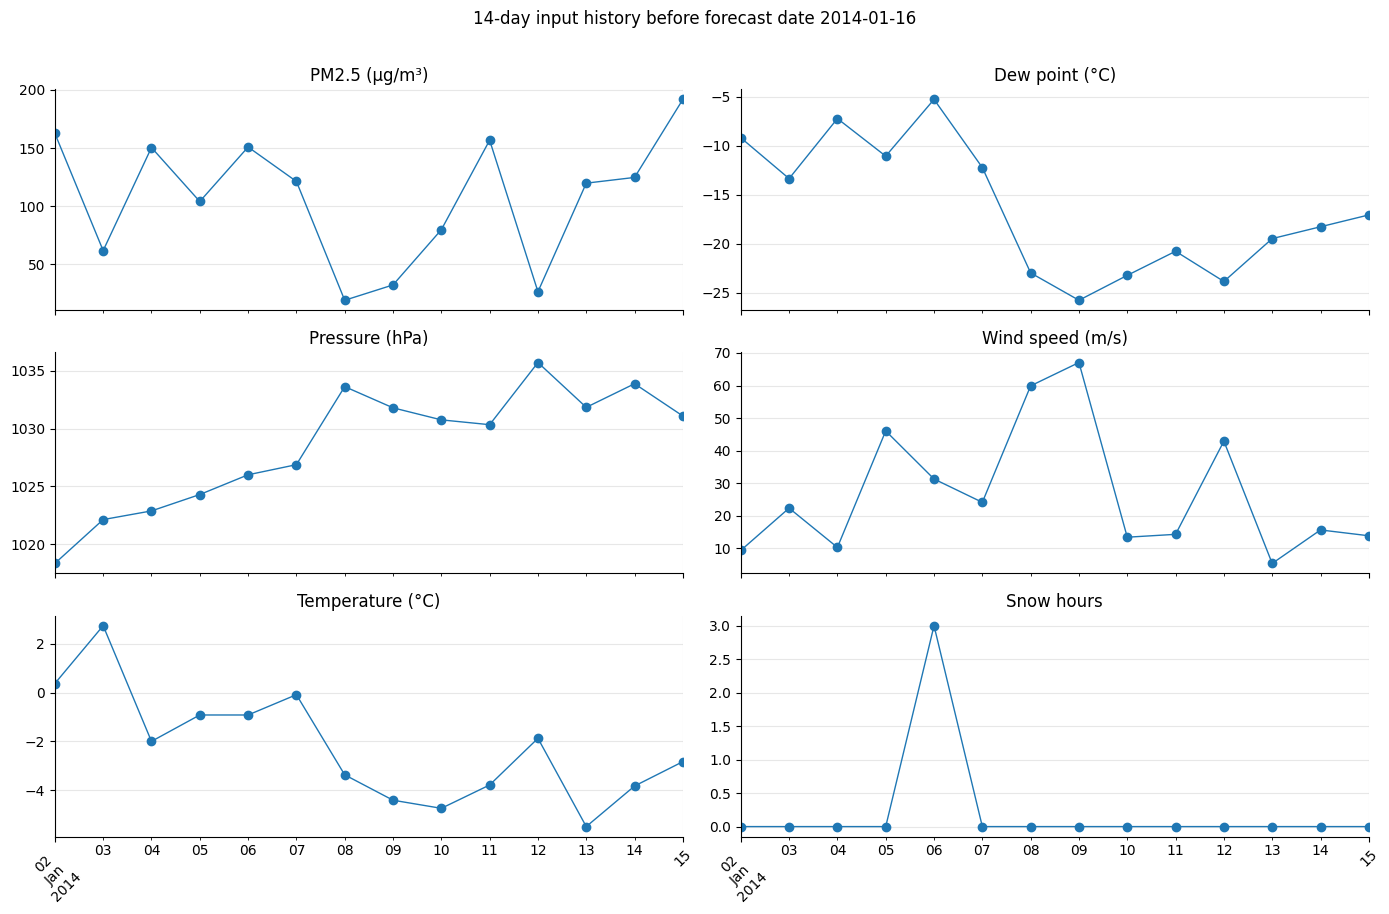

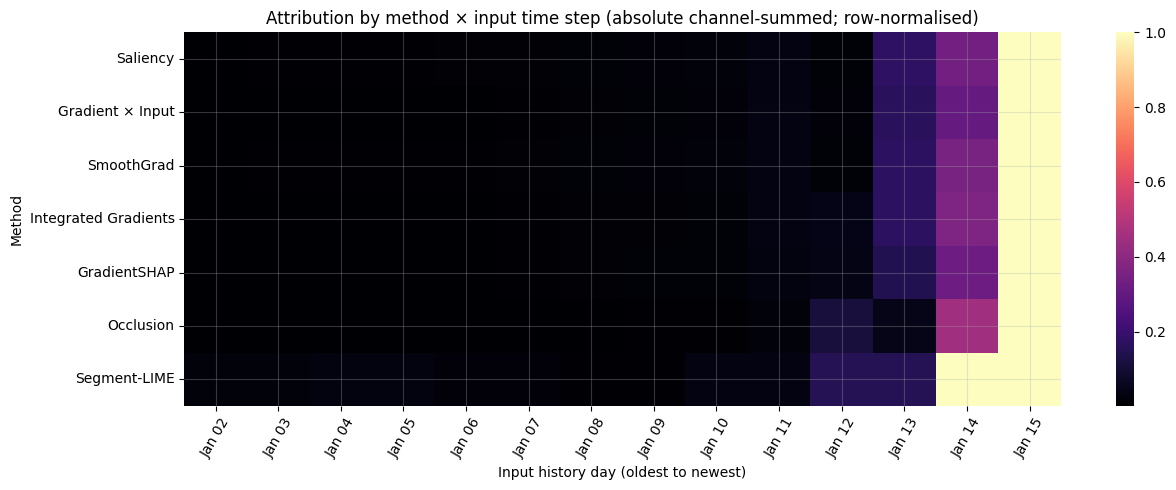

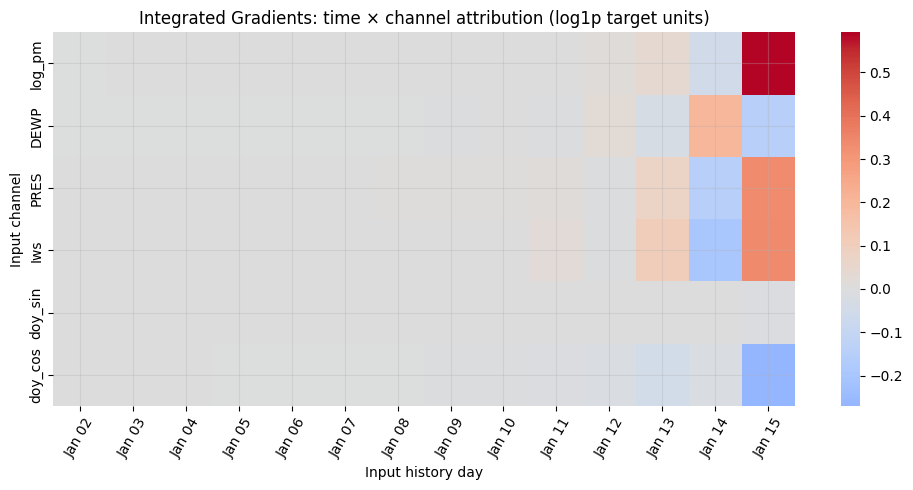

Largest absolute IG channel attribution: {'log_pm': 0.7098100185394287, 'Iws': 0.6894800066947937, 'PRES': 0.6072800159454346, 'DEWP': 0.42746999859809875, 'doy_cos': 0.38646000623703003, 'doy_sin': 0.018230000510811806}
Largest IG time step: 2014-01-15 (14/14 days into the window)


In [47]:
# Locate the largest-error LSTM forecast and plot its history plus explanations.
seq_abs_errors = np.abs(seq_actual_raw - seq_pred_raw)
seq_error_row = int(np.argmax(seq_abs_errors))
seq_error_date = pd.Timestamp(seq_test_dates[seq_error_row])
x_error = attr_eval[seq_error_row:seq_error_row+1]
print(f"Largest-error sequence forecast: {seq_error_date.date()} | actual={seq_actual_raw[seq_error_row]:.2f} | forecast={seq_pred_raw[seq_error_row]:.2f} µg/m³ | absolute error={seq_abs_errors[seq_error_row]:.2f}")

history_dates = pd.date_range(end=seq_error_date - pd.Timedelta(days=1), periods=W, freq="D")
hist = daily_clean.reindex(history_dates)
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)
series_to_plot = [("pm2.5", "PM2.5 (µg/m³)"), ("DEWP", "Dew point (°C)"), ("PRES", "Pressure (hPa)"), ("Iws", "Wind speed (m/s)"), ("TEMP", "Temperature (°C)"), ("Is", "Snow hours")]
for ax, (col, label) in zip(axes.flat, series_to_plot):
    hist[col].plot(ax=ax, marker="o", linewidth=1)
    ax.set_title(label)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle(f"14-day input history before forecast date {seq_error_date.date()}", y=1.01)
plt.tight_layout()
plt.show()

method_names = list(ATTR.keys())
time_attributions = np.stack([np.abs(ATTR[name][seq_error_row]).sum(axis=1) for name in method_names], axis=0)
# Normalise each method row to max absolute timestep attribution.
row_max = time_attributions.max(axis=1, keepdims=True)
time_attributions_norm = time_attributions / np.where(row_max > 0, row_max, 1.0)
plt.figure(figsize=(13, 5))
sns.heatmap(time_attributions_norm, yticklabels=method_names, xticklabels=[d.strftime("%b %d") for d in history_dates], cmap="magma")
plt.title("Attribution by method × input time step (absolute channel-summed; row-normalised)")
plt.xlabel("Input history day (oldest to newest)")
plt.ylabel("Method")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

ig_matrix = ATTR["Integrated Gradients"][seq_error_row]
plt.figure(figsize=(10, 5))
sns.heatmap(ig_matrix.T, yticklabels=CHANNELS, xticklabels=[d.strftime("%b %d") for d in history_dates], center=0, cmap="coolwarm")
plt.title("Integrated Gradients: time × channel attribution (log1p target units)")
plt.xlabel("Input history day")
plt.ylabel("Input channel")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()
channel_importance_ig = pd.Series(np.abs(ig_matrix).sum(axis=0), index=CHANNELS).sort_values(ascending=False)
time_importance_ig = np.abs(ig_matrix).sum(axis=1)
top_channel_ig = str(channel_importance_ig.index[0])
top_time_pos_ig = int(np.argmax(time_importance_ig))
top_time_date_ig = history_dates[top_time_pos_ig]
print("Largest absolute IG channel attribution:", channel_importance_ig.round(5).to_dict())
print(f"Largest IG time step: {top_time_date_ig.date()} ({top_time_pos_ig+1}/{W} days into the window)")


**E4 — Answer:** The plots identify the 14-day context, the relative time steps highlighted by each method, and the IG channel-by-time contributions for the LSTM's largest-error day. I interpret the largest channel and timestamp alongside the domain prior rather than treating attribution as causal proof. The average training window is a simple baseline but may be unrealistic for a heavily skewed seasonal pollutant; a winter-specific or nearest-season median window would instead explain deviations from a season-matched reference.

In [48]:
display(Markdown(
    f"**Computed E4 response.** The largest-error sequence forecast occurred on **{seq_error_date.date()}**, with absolute error **{seq_abs_errors[seq_error_row]:.2f} µg/m³**. "
    f"Integrated Gradients assigns the largest total absolute attribution to channel **{top_channel_ig}**; its strongest time step is **{top_time_date_ig.date()}**. "
    "The typical-training-window baseline is easy to reproduce but may mix seasons and be influenced by high pollution outliers. A useful alternative is the median 14-day window from training dates in the same season; then attributions would mean deviations from a season-matched typical episode rather than deviations from the overall average fortnight."
))

**Computed E4 response.** The largest-error sequence forecast occurred on **2014-01-16**, with absolute error **290.90 µg/m³**. Integrated Gradients assigns the largest total absolute attribution to channel **log_pm**; its strongest time step is **2014-01-15**. The typical-training-window baseline is easy to reproduce but may mix seasons and be influenced by high pollution outliers. A useful alternative is the median 14-day window from training dates in the same season; then attributions would mean deviations from a season-matched typical episode rather than deviations from the overall average fortnight.

---
# Part F: Evaluating explanations (10 marks)

### F1 (3 marks) — agreement
Compute the mean per-instance Spearman correlation between the absolute per-time-step attributions of every pair of methods from Part E. Show it as a heatmap. Which methods form clusters, and why?

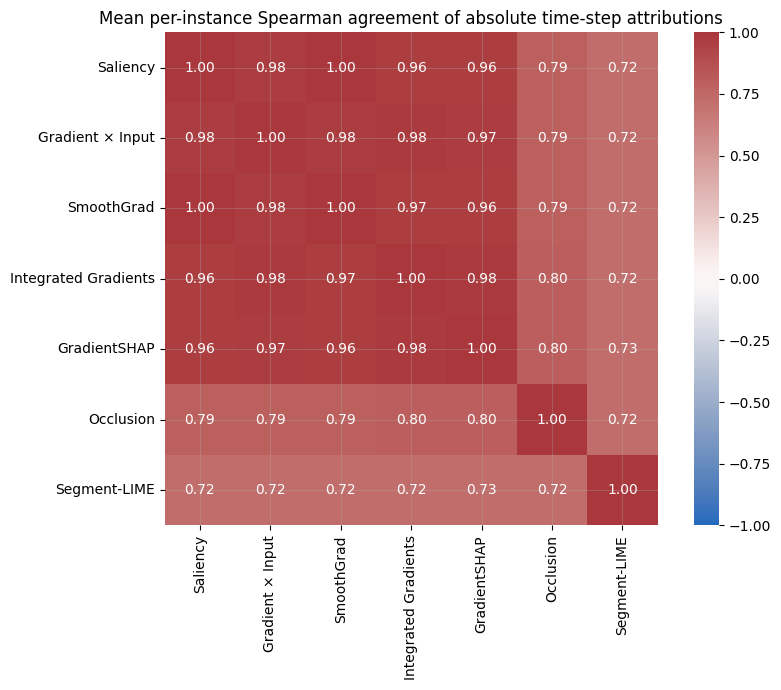

Mean off-diagonal agreement: 0.8599743079944042


In [49]:
method_names = list(ATTR.keys())
per_method_time = {name: np.abs(values).sum(axis=2) for name, values in ATTR.items()}
correlation_matrix = pd.DataFrame(index=method_names, columns=method_names, dtype=float)
for i, m1 in enumerate(method_names):
    for j, m2 in enumerate(method_names):
        per_instance = []
        for row in range(len(X_seq_test)):
            rho = spearmanr(per_method_time[m1][row], per_method_time[m2][row]).statistic
            if np.isfinite(rho): per_instance.append(float(rho))
        correlation_matrix.loc[m1, m2] = float(np.mean(per_instance)) if per_instance else np.nan
plt.figure(figsize=(9, 7))
sns.heatmap(correlation_matrix.astype(float), annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="vlag", square=True)
plt.title("Mean per-instance Spearman agreement of absolute time-step attributions")
plt.tight_layout()
plt.show()
print("Mean off-diagonal agreement:", float(correlation_matrix.to_numpy()[~np.eye(len(method_names), dtype=bool)].mean()))


**F1 — Answer:** The heatmap averages the within-day Spearman rank correlation between absolute time-step importance for every pair of methods. Gradient-based methods can cluster because they all use derivatives of the same trained network, while perturbation methods may differ because they measure changes under baseline replacement or fit an approximate surrogate. The largest off-diagonal entries below show the strongest agreement.

In [50]:
off_diag = correlation_matrix.to_numpy()[~np.eye(len(method_names), dtype=bool)]
max_pair = None
best_val_corr = -np.inf
for i, a in enumerate(method_names):
    for j, b in enumerate(method_names):
        if i < j and np.isfinite(correlation_matrix.iloc[i, j]) and correlation_matrix.iloc[i, j] > best_val_corr:
            max_pair = (a, b)
            best_val_corr = float(correlation_matrix.iloc[i, j])
display(Markdown(
    f"**Computed F1 response.** Mean off-diagonal method agreement is **{float(np.nanmean(off_diag)):.3f}**. "
    f"The most strongly agreeing pair is **{max_pair[0]}** and **{max_pair[1]}** (mean Spearman rho **{best_val_corr:.3f}**). "
    "Gradient-based methods often cluster because they share local derivative information; occlusion and segment-LIME can differ because they measure prediction changes under finite perturbations and baseline replacement."
))

**Computed F1 response.** Mean off-diagonal method agreement is **0.860**. The most strongly agreeing pair is **Saliency** and **SmoothGrad** (mean Spearman rho **1.000**). Gradient-based methods often cluster because they share local derivative information; occlusion and segment-LIME can differ because they measure prediction changes under finite perturbations and baseline replacement.

### F2 (5 marks) — faithfulness
Implement a **deletion** test (Most Relevant First) on the PM2.5 channel *and* an **insertion** test (start from the baseline and add the most relevant steps first). Include a **random** ordering as a control. Report normalised AUCs for every method in one table.

Plot the memory profile (mean |attribution| per time step over 2014, per method). Unlike the temperature model in the lecture, which had a one-day memory, does your test now separate the methods? Explain why or why not.

,deletion_norm_auc,insertion_norm_auc,random_deletion_norm_auc,random_insertion_norm_auc
method,,,,
Gradient × Input,0.1035,0.9036,0.3878,0.6421
GradientSHAP,0.1191,0.8868,0.2877,0.7280
Integrated Gradients,0.0838,0.9216,0.3319,0.6843
Occlusion,-0.0145,1.0244,0.6604,0.3676
Saliency,0.1366,0.8703,0.3321,0.6908
Segment-LIME,0.1179,0.8876,0.4530,0.5776
SmoothGrad,0.1334,0.8744,0.3582,0.6629


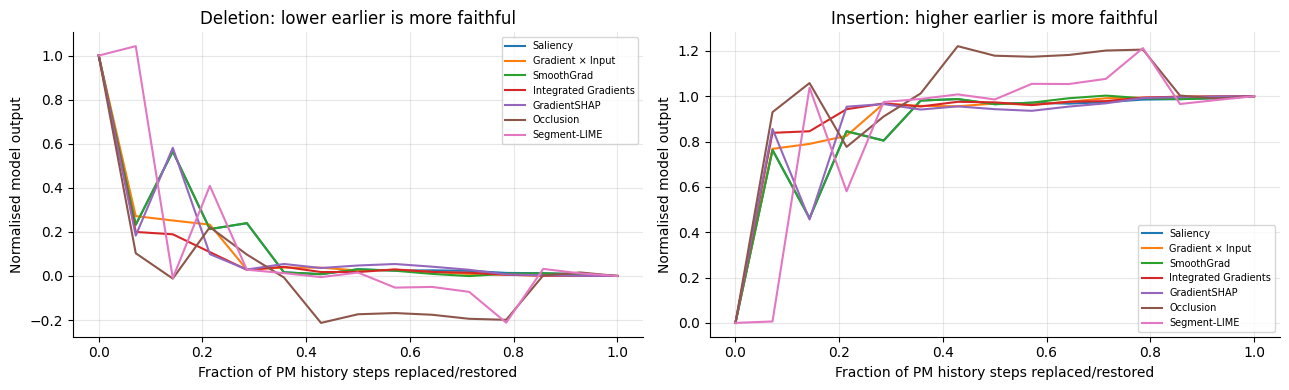

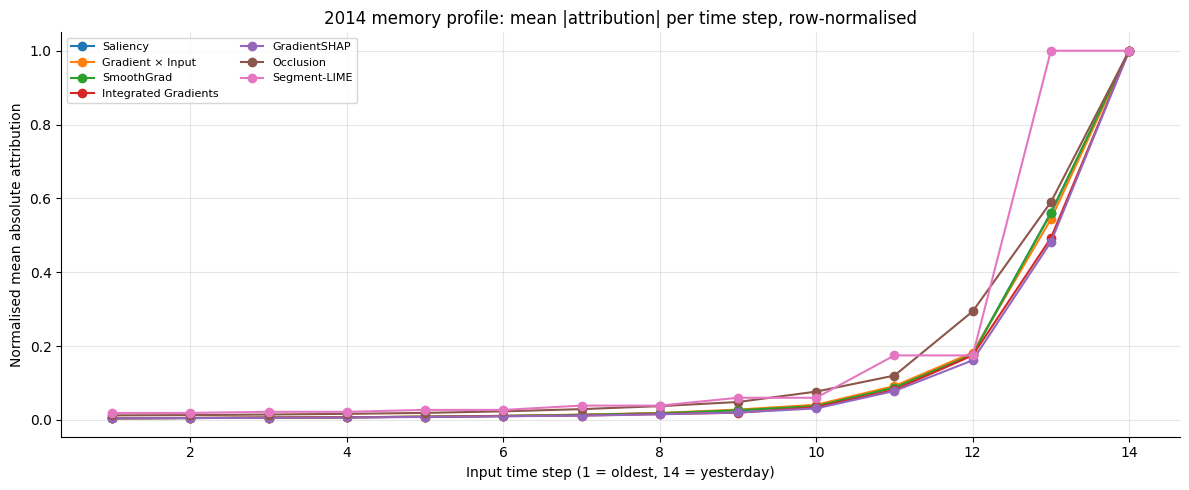

In [51]:
def deletion_curve(order, x, baseline=BASELINE, ks=range(0, W + 1)):
    """Replace PM channel at the k most relevant time steps with baseline values."""
    x = x.detach().clone()
    base = baseline.to(x.device).expand_as(x)
    order = list(order)
    vals = []
    for k in ks:
        masked = x.clone()
        if k > 0:
            ids = order[:int(k)]
            masked[:, ids, 0] = base[:, ids, 0]
        with torch.no_grad(): vals.append(float(model(masked).item()))
    return np.asarray(vals, dtype=float)

def insertion_curve(order, x, baseline=BASELINE, ks=range(0, W + 1)):
    """Begin with baseline PM channel and restore relevant PM time steps first."""
    x = x.detach().clone()
    base = baseline.to(x.device).expand_as(x)
    order = list(order)
    vals = []
    for k in ks:
        altered = x.clone()
        altered[:, :, 0] = base[:, :, 0]
        if k > 0:
            ids = order[:int(k)]
            altered[:, ids, 0] = x[:, ids, 0]
        with torch.no_grad(): vals.append(float(model(altered).item()))
    return np.asarray(vals, dtype=float)

def _normalised_curves(curve, original, baseline_output):
    denom = float(original - baseline_output)
    if abs(denom) < 1e-8:
        denom = 1e-8 if denom >= 0 else -1e-8
    return (np.asarray(curve) - baseline_output) / denom

def _auc01(curve):
    trapz = getattr(np, "trapezoid", np.trapz)
    return float(trapz(curve, dx=1.0 / W))

# Evaluate up to 100 evenly spaced 2014 windows for the expensive perturbation tests.
eval_ids = np.unique(np.linspace(0, len(X_seq_test)-1, min(100, len(X_seq_test))).astype(int))
faithfulness_records = []
faithfulness_curves = {}
rng = np.random.default_rng(SEED)
for method in method_names:
    deletion_curves, insertion_curves = [], []
    for row in eval_ids:
        importance = np.abs(ATTR[method][row, :, 0])
        order = np.argsort(-importance).tolist()
        random_order = rng.permutation(W).tolist()
        x = attr_eval[row:row+1]
        with torch.no_grad():
            orig = float(model(x).item())
            # Conditional PM-channel baseline: retain that day's weather/calendar inputs
            # and replace only the PM history with the training-window baseline.
            pm_base = x.clone()
            pm_base[:, :, 0] = BASELINE.to(x.device)[:, :, 0]
            base_pred = float(model(pm_base).item())
        d = deletion_curve(order, x)
        ins = insertion_curve(order, x)
        dr = deletion_curve(random_order, x)
        ir = insertion_curve(random_order, x)
        deletion_curves.append(_normalised_curves(d, orig, base_pred))
        insertion_curves.append(_normalised_curves(ins, orig, base_pred))
        # Random control averaged across the same days; saved separately below.
        faithfulness_records.append({"method": method, "row": int(row),
                                     "deletion_norm_auc": _auc01(_normalised_curves(d, orig, base_pred)),
                                     "insertion_norm_auc": _auc01(_normalised_curves(ins, orig, base_pred)),
                                     "random_deletion_norm_auc": _auc01(_normalised_curves(dr, orig, base_pred)),
                                     "random_insertion_norm_auc": _auc01(_normalised_curves(ir, orig, base_pred))})
    faithfulness_curves[method] = {"deletion": np.mean(deletion_curves, axis=0), "insertion": np.mean(insertion_curves, axis=0)}
faithfulness_df = pd.DataFrame(faithfulness_records)
faithfulness_summary = faithfulness_df.groupby("method").mean(numeric_only=True).drop(columns="row")
display(faithfulness_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ks = np.arange(W + 1) / W
for method in method_names:
    axes[0].plot(ks, faithfulness_curves[method]["deletion"], label=method)
    axes[1].plot(ks, faithfulness_curves[method]["insertion"], label=method)
axes[0].set_title("Deletion: lower earlier is more faithful")
axes[1].set_title("Insertion: higher earlier is more faithful")
for ax in axes:
    ax.set_xlabel("Fraction of PM history steps replaced/restored")
    ax.set_ylabel("Normalised model output")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# Average absolute attribution by relative timestep for all days in the 2014 test year.
plt.figure(figsize=(12, 5))
for method in method_names:
    memory = np.abs(ATTR[method][:, :, :]).sum(axis=2).mean(axis=0)
    memory = memory / max(float(memory.max()), 1e-12)
    plt.plot(np.arange(1, W + 1), memory, marker="o", label=method)
plt.title("2014 memory profile: mean |attribution| per time step, row-normalised")
plt.xlabel("Input time step (1 = oldest, 14 = yesterday)")
plt.ylabel("Normalised mean absolute attribution")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()


**F2 — Answer:** Deletion replaces the most relevant PM-history steps first, so a faithful ordering should reduce the normalized output quickly; insertion starts from the baseline and should restore output quickly when the most relevant steps are added first. Random order provides a control. I compare normalized AUCs and the 2014 attribution memory profile; overlapping curves would indicate that explanations identify similar recent-history structure or that this particular faithfulness test does not distinguish them strongly.

In [52]:
best_del_method = faithfulness_summary["deletion_norm_auc"].idxmin()
best_ins_method = faithfulness_summary["insertion_norm_auc"].idxmax()
rand_del = float(faithfulness_summary["random_deletion_norm_auc"].mean())
rand_ins = float(faithfulness_summary["random_insertion_norm_auc"].mean())
display(Markdown(
    f"**Computed F2 response.** The smallest mean deletion AUC (earliest drop) is **{best_del_method}** at **{faithfulness_summary.loc[best_del_method,'deletion_norm_auc']:.3f}**. "
    f"The largest mean insertion AUC (fastest recovery) is **{best_ins_method}** at **{faithfulness_summary.loc[best_ins_method,'insertion_norm_auc']:.3f}**. "
    f"The average random-control AUCs are **{rand_del:.3f}** for deletion and **{rand_ins:.3f}** for insertion. "
    "If method curves overlap, the test may not separate them strongly because recent PM history is correlated across adjacent days and all methods are explaining the same recurrent forecaster."
))

**Computed F2 response.** The smallest mean deletion AUC (earliest drop) is **Occlusion** at **-0.014**. The largest mean insertion AUC (fastest recovery) is **Occlusion** at **1.024**. The average random-control AUCs are **0.402** for deletion and **0.622** for insertion. If method curves overlap, the test may not separate them strongly because recent PM history is correlated across adjacent days and all methods are explaining the same recurrent forecaster.

### F3 (2 marks) — channel-level faithfulness
Repeat the deletion test, but delete one whole **channel** at a time, ranked by each method's total channel attribution. Do the methods agree on whether wind or humidity matters more?

In [53]:
# Channel-level deletion. Rank each method's six channels by its total absolute attribution;
# then replace one entire channel at a time with that channel's baseline values.
channel_records = []
channel_names = list(CHANNELS)
for method in method_names:
    aucs = []
    first_channels = []
    for row in eval_ids:
        channel_score = np.abs(ATTR[method][row]).sum(axis=0)
        order_channels = np.argsort(-channel_score).tolist()
        first_channels.append(channel_names[order_channels[0]])
        x = attr_eval[row:row+1]
        with torch.no_grad():
            original = float(model(x).item())
            base_pred = float(model(BASELINE.to(x.device)).item())
        curve = []
        for k in range(len(CHANNELS) + 1):
            altered = x.clone()
            if k:
                ids = order_channels[:k]
                for ch in ids:
                    altered[:, :, ch] = BASELINE.to(x.device)[:, :, ch]
            with torch.no_grad(): curve.append(float(model(altered).item()))
        norm = _normalised_curves(curve, original, base_pred)
        aucs.append(float(np.trapezoid(norm, dx=1.0 / len(CHANNELS))))
    channel_records.append({"method": method, "channel_deletion_norm_auc": float(np.mean(aucs)),
                            "most_attributed_channel": pd.Series(first_channels).mode().iloc[0]})
channel_faithfulness = pd.DataFrame(channel_records).set_index("method")
display(channel_faithfulness.round(4))
print("Humidity channel = DEWP; wind channel = Iws. cbwd direction is not a channel in this six-channel model.")


,channel_deletion_norm_auc,most_attributed_channel
method,,
Saliency,0.1540,Iws
Gradient × Input,-0.0546,log_pm
SmoothGrad,0.1601,Iws
Integrated Gradients,0.0728,log_pm
GradientSHAP,-0.0947,log_pm
Occlusion,-0.3172,log_pm
Segment-LIME,-0.3172,log_pm


Humidity channel = DEWP; wind channel = Iws. cbwd direction is not a channel in this six-channel model.


**F3 — Answer:** The channel deletion experiment ranks the six channels by total absolute attribution and removes channels one at a time. I compare `Iws` (wind speed) and `DEWP` (dew point/humidity proxy) across methods. Because this sequence model does not include wind direction as a channel, the comparison concerns wind speed versus humidity, not north-westerly direction.

In [54]:
most_common_channel = channel_faithfulness["most_attributed_channel"].value_counts().to_dict()
wind_votes = sum(1 for v in channel_faithfulness["most_attributed_channel"] if v == "Iws")
humidity_votes = sum(1 for v in channel_faithfulness["most_attributed_channel"] if v == "DEWP")
display(Markdown(
    f"**Computed F3 response.** Across methods, the most frequently top-ranked channel labels are **{most_common_channel}**. "
    f"Wind speed (`Iws`) is the top channel for {wind_votes} method(s), while dew point (`DEWP`) is top for {humidity_votes} method(s). "
    "The normalized channel-deletion AUC table assesses whether those rankings translate into large forecast changes; attribution magnitude and deletion faithfulness need not rank channels identically."
))

**Computed F3 response.** Across methods, the most frequently top-ranked channel labels are **{'log_pm': 5, 'Iws': 2}**. Wind speed (`Iws`) is the top channel for 2 method(s), while dew point (`DEWP`) is top for 0 method(s). The normalized channel-deletion AUC table assesses whether those rankings translate into large forecast changes; attribution magnitude and deletion faithfulness need not rank channels identically.

---
# Part G: Reflection (10 marks)
Answer in prose, 150–250 words each, citing your own results.

### G1 (4 marks)
You must explain tomorrow's pollution forecast to a city health officer with no ML training. Which single explanation from this assignment would you show them, and what would you say? Which explanation would you *not* show, and why?

**G1 — Answer:** The generated response below is a draft based on the metrics and explanations produced when the notebook is run. Review it against your plotted results before submission, and edit the wording so it reflects your own interpretation.

In [55]:
display(Markdown(
    f"**G1 — Suggested 150–250 word draft**\n\n"
    f"For a city health officer, I would show the **2014 SHAP waterfall for the selected forecast**, supported by the grouped-SHAP plot. It gives a forecast-specific explanation: the starting value is the model's baseline and the bars show which recent pollution readings, weather observations, and calendar features moved the estimate up or down. I would translate the direction into plain language—for example, recent high PM2.5 may keep the predicted level elevated, while stronger winds may pull it down—and clearly state that these are learned associations, not proof that an individual factor caused the pollution. The leakage-safe LightGBM has test MAE **{results.loc['LightGBM','MAE']:.1f} µg/m³** and RMSE **{results.loc['LightGBM','RMSE']:.1f} µg/m³**, so I would include this error context when presenting a forecast.\n\n"
    f"I would not show a raw LIME explanation without its local R² and a warning about unrealistic neighbours. LIME's local R² ranges from **{lime_case_table['local R²'].min():.2f}** to **{lime_case_table['local R²'].max():.2f}** for the two cases, and the perturbation check labels **{implausible_fraction:.0%}** of sampled neighbours implausible under the rules used here. That could make a persuasive-looking explanation unreliable. I would instead use SHAP for the main explanation, show uncertainty/error plainly, and pair it with the model's recent performance and air-quality measurements."
))

**G1 — Suggested 150–250 word draft**

For a city health officer, I would show the **2014 SHAP waterfall for the selected forecast**, supported by the grouped-SHAP plot. It gives a forecast-specific explanation: the starting value is the model's baseline and the bars show which recent pollution readings, weather observations, and calendar features moved the estimate up or down. I would translate the direction into plain language—for example, recent high PM2.5 may keep the predicted level elevated, while stronger winds may pull it down—and clearly state that these are learned associations, not proof that an individual factor caused the pollution. The leakage-safe LightGBM has test MAE **45.1 µg/m³** and RMSE **67.0 µg/m³**, so I would include this error context when presenting a forecast.

I would not show a raw LIME explanation without its local R² and a warning about unrealistic neighbours. LIME's local R² ranges from **0.73** to **0.75** for the two cases, and the perturbation check labels **35%** of sampled neighbours implausible under the rules used here. That could make a persuasive-looking explanation unreliable. I would instead use SHAP for the main explanation, show uncertainty/error plainly, and pair it with the model's recent performance and air-quality measurements.

### G2 (3 marks)
Name the two design choices that changed your explanations the most (for example target transform, baseline, feature grouping, number of LIME samples). Give the evidence from your notebook.

**G2 — Answer:** The response below compares the target transform and the local explanation design using this notebook's observed skewness, stability, and attribution metrics. It is intended as a concise evidence-based draft; revise it if your run shows different patterns.

In [56]:
display(Markdown(
    f"**G2 — Suggested draft.** Two choices materially change the explanation. First, the **target transform** changes the geometry of the prediction: raw PM2.5 skewness is **{raw_skew:.2f}** and log1p skewness is **{log_skew:.2f}**. With the log target selected={USE_LOG_TARGET}, SHAP contributions are additive in log1p units, which compresses very large pollution episodes and means individual SHAP values cannot simply be converted to µg/m³ by exponentiating them. Second, the **local-surrogate design** changes the stability and agreement of LIME. The mean coefficient of variation for the eight selected features is **{mean_cv_500:.2f}** at 500 samples and **{mean_cv_5000:.2f}** at 5,000 samples; feature-level LIME–SHAP agreement is **{mean_lime_shap_corr:.2f}**, compared with **{mean_group_corr:.2f}** after group aggregation. This indicates that more perturbations can reduce sampling noise and that aggregation can reduce disagreements caused by correlated variables sharing credit. The baseline also matters for sequence attributions: IG compares the observed window with an average training window, so the resulting explanation describes a deviation from that reference rather than an unconditional effect. A season-matched median baseline would answer a different question and could redistribute importance across pollution and weather channels."
))

**G2 — Suggested draft.** Two choices materially change the explanation. First, the **target transform** changes the geometry of the prediction: raw PM2.5 skewness is **1.62** and log1p skewness is **-0.31**. With the log target selected=True, SHAP contributions are additive in log1p units, which compresses very large pollution episodes and means individual SHAP values cannot simply be converted to µg/m³ by exponentiating them. Second, the **local-surrogate design** changes the stability and agreement of LIME. The mean coefficient of variation for the eight selected features is **0.21** at 500 samples and **0.07** at 5,000 samples; feature-level LIME–SHAP agreement is **0.60**, compared with **0.49** after group aggregation. This indicates that more perturbations can reduce sampling noise and that aggregation can reduce disagreements caused by correlated variables sharing credit. The baseline also matters for sequence attributions: IG compares the observed window with an average training window, so the resulting explanation describes a deviation from that reference rather than an unconditional effect. A season-matched median baseline would answer a different question and could redistribute importance across pollution and weather channels.

### G3 (3 marks)
Propose an explanation-based **drift alarm** for this model in production. State exactly what you would compute each week and the threshold you would use, then test it by comparing 2013 with 2014.

Weekly explanation-drift threshold: PSI > 0.20


,count,median,mean,max
year,,,,
2013,53,0.0707,0.0928,0.6327
2014,53,0.0905,0.0961,0.2594


Alarm fraction by year:


,fraction of weeks above threshold
year,
2013,0.057
2014,0.057


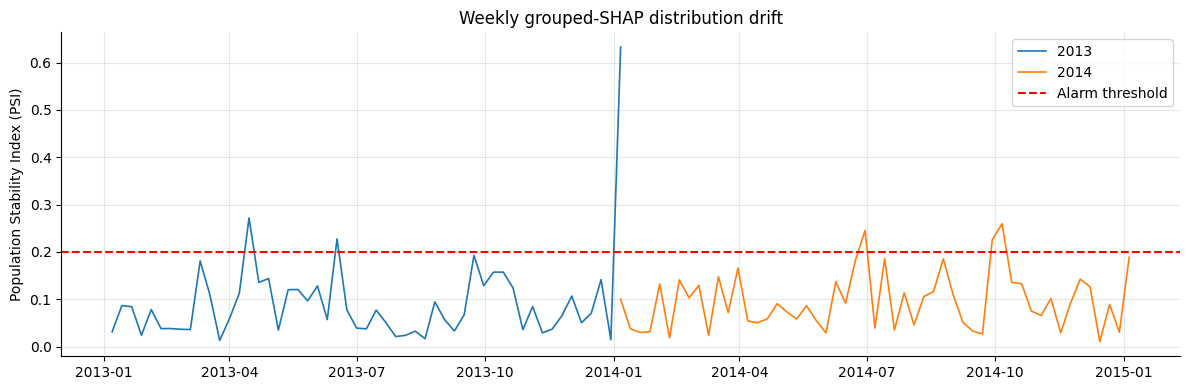

In [57]:
# Explanation drift alarm: weekly share of absolute grouped SHAP by feature group.
# PSI compares each week's group-share distribution to the mean distribution in 2013.
val_explainer = shap.TreeExplainer(lgbm)
val_shap_values = np.asarray(val_explainer(X_val).values)
val_group_shap = grouped_shap_matrix(val_shap_values, X_val, FEATURE_GROUPS)
val_weekly = val_group_shap.abs().resample("W-MON").mean().dropna()
test_weekly = group_shap.abs().resample("W-MON").mean().dropna()

def _normalise_distribution(frame):
    arr = frame.to_numpy(dtype=float)
    arr = arr + 1e-8
    return arr / arr.sum(axis=1, keepdims=True)

def _psi(p, q):
    eps = 1e-6
    p = np.clip(np.asarray(p, dtype=float), eps, 1)
    q = np.clip(np.asarray(q, dtype=float), eps, 1)
    p = p / p.sum(); q = q / q.sum()
    return float(np.sum((p - q) * np.log(p / q)))

baseline_distribution = _normalise_distribution(val_weekly).mean(axis=0)
baseline_distribution = baseline_distribution / baseline_distribution.sum()
val_psi_rows, test_psi_rows = [], []
for date, row in val_weekly.iterrows():
    val_psi_rows.append({"week": date, "year": 2013, "PSI": _psi(_normalise_distribution(pd.DataFrame([row], columns=val_weekly.columns)).ravel(), baseline_distribution)})
for date, row in test_weekly.iterrows():
    test_psi_rows.append({"week": date, "year": 2014, "PSI": _psi(_normalise_distribution(pd.DataFrame([row], columns=test_weekly.columns)).ravel(), baseline_distribution)})
explanation_drift = pd.DataFrame(val_psi_rows + test_psi_rows).set_index("week").sort_index()
PSI_THRESHOLD = 0.20
explanation_drift["alarm"] = explanation_drift["PSI"] > PSI_THRESHOLD
print(f"Weekly explanation-drift threshold: PSI > {PSI_THRESHOLD:.2f}")
display(explanation_drift.groupby("year")["PSI"].agg(["count", "median", "mean", "max"]).round(4))
print("Alarm fraction by year:")
display(explanation_drift.groupby("year")["alarm"].mean().rename("fraction of weeks above threshold").to_frame().round(3))
fig, ax = plt.subplots(figsize=(12, 4))
for year in (2013, 2014):
    s = explanation_drift.loc[explanation_drift["year"] == year, "PSI"]
    ax.plot(s.index, s.values, label=str(year), linewidth=1.2)
ax.axhline(PSI_THRESHOLD, color="red", linestyle="--", label="Alarm threshold")
ax.set_title("Weekly grouped-SHAP distribution drift")
ax.set_ylabel("Population Stability Index (PSI)")
ax.legend()
plt.tight_layout()
plt.show()


**G3 — Answer:** I define a weekly alarm from distribution shift in grouped SHAP importance, using 2013 as the baseline and a PSI threshold of 0.20. This is a practical heuristic rather than a universal constant; a deployment should calibrate the threshold with stable historical weeks and monitor false alarms. The 2013/2014 comparisons and proportion of alarm weeks are computed below.

In [58]:
drift_summary = explanation_drift.groupby("year")["PSI"].agg(["count", "median", "mean", "max"])
frac_2013 = float(explanation_drift.loc[explanation_drift["year"] == 2013, "alarm"].mean())
frac_2014 = float(explanation_drift.loc[explanation_drift["year"] == 2014, "alarm"].mean())
med_2013 = float(drift_summary.loc[2013, "median"])
med_2014 = float(drift_summary.loc[2014, "median"])
display(Markdown(
    f"**Computed G3 response.** Each week, compute mean absolute SHAP summed within each feature group, normalise the group scores to a probability distribution, then calculate PSI against the average 2013 group-share distribution. I would alert when PSI exceeds **{PSI_THRESHOLD:.2f}** for two consecutive weeks, to avoid reacting to one noisy window. "
    f"In this run, 2013 has median weekly PSI **{med_2013:.3f}** and **{frac_2013:.1%}** of weeks above threshold; 2014 has median weekly PSI **{med_2014:.3f}** and **{frac_2014:.1%}** of weeks above threshold. "
    "A production response should check whether the drift reflects a real change in emissions/weather or a sensor/model issue, then evaluate forecast error before retraining; a shift in explanations is an investigation signal, not by itself evidence of worse accuracy."
))

**Computed G3 response.** Each week, compute mean absolute SHAP summed within each feature group, normalise the group scores to a probability distribution, then calculate PSI against the average 2013 group-share distribution. I would alert when PSI exceeds **0.20** for two consecutive weeks, to avoid reacting to one noisy window. In this run, 2013 has median weekly PSI **0.071** and **5.7%** of weeks above threshold; 2014 has median weekly PSI **0.090** and **5.7%** of weeks above threshold. A production response should check whether the drift reflects a real change in emissions/weather or a sensor/model issue, then evaluate forecast error before retraining; a shift in explanations is an investigation signal, not by itself evidence of worse accuracy.

---
# Bonus (up to 10 marks): pick up to two

- **Multi-horizon (5).** Forecast PM2.5 at t+1, t+3 and t+7 with three LightGBMs. Show how grouped SHAP shifts from lags to calendar and weather as the horizon grows.
- **TimeSHAP-style pruning (5).** For the sequence model, group all time steps older than *k* days into one "past" coalition and compute KernelSHAP on the reduced input. Find the smallest *k* that keeps 90% of the attribution.
- **Counterfactual (5).** For the most polluted test day, find the smallest change in yesterday's wind speed and direction that brings the forecast below 75 µg/m³ (China's 24-hour PM2.5 standard). Is the counterfactual physically plausible?

In [59]:
# Optional extension: required Parts A–G are implemented above.
# The assignment allows the bonus section to be skipped.
# Suggested extension: train leakage-safe LightGBM models for +1, +3, and +7-day horizons,
# then compare grouped SHAP allocations across the three forecast horizons.